# Co-expression networks with hdWGCNA (Python)

**Author:** Tahila Andrighetti  
**Last updated:** October 2026

> Code review, refactoring and documentation were developed with the assistance
> of [Claude Code](https://claude.com/claude-code) (Anthropic). All text and analytical
> choices were reviewed by the author.

# Overview

This tutorial shows how to build a gene co-expression network from single-cell
RNA-seq data with hdWGCNA. WGCNA groups genes into **modules**: sets of genes
with similar expression patterns [Langfelder and Horvath, 2008]. hdWGCNA adapts
WGCNA to single-cell data, using metacells [Morabito et al., 2023].

The workflow works for any dataset with cell groups (cell types, clusters or
stages), biological samples and, if you have them, experimental conditions.

## About the example dataset


> **Example dataset.** To show each step, we use bone marrow neutrophils from
> the public dataset of Sheng et al. (2025), which compared germ-free (GF) and
> specific pathogen-free (SPF) mice. Notes marked **Example dataset** explain
> choices that depend on these data. For your own data, change the parameters
> cell and check these choices again.


Sheng et al. (2025) profiled bone marrow and peripheral blood immune cells of
GF and SPF mice with single-cell RNA-seq, to study how the absence of
microbiota affects immune development. This tutorial uses only the **bone
marrow** samples, and only the **neutrophil lineage**:

| Sample | Condition | GEO sample | SRA run |
|---|---|---|---|
| `49` | SPF | GSM8943511 | SRR33239249 |
| `50` | GF | GSM8943510 | SRR33239250 |

- Mice: Kunming (KM) strain, male, 10 weeks old.
- Library: 10x Genomics Chromium Single Cell 3' v3.1. Data: GEO
  [GSE295200](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE295200).
- We processed the raw data again (Cell Ranger, SoupX, QC, integration) and
  annotated the neutrophils in the maturation stages G0 to G5c of Xie et al.
  (2020). The original study used another annotation (populations P1 to P4).

> **Caveat: one sample per condition.** This dataset has **one animal per
> condition** (n = 1 GF and n = 1 SPF in the bone marrow). This has three
> consequences:
>
> 1. **Condition and sample are the same factor.** A difference between GF and
>    SPF cannot be separated from the normal difference between two animals, or
>    between two libraries. Kunming is an outbred stock, so differences between
>    individual animals can be large.
> 2. **No statistical test between conditions is valid.** With n = 1 per group,
>    there is no estimate of the variation between animals. Tests that use cells
>    or metacells as replicates give false positives (pseudoreplication)
>    [Zimmerman et al., 2021; Squair et al., 2021].
> 3. **Results are descriptive.** Building the network with both samples
>    together is fine to show the method and to find gene programs along
>    maturation. But any GF vs SPF difference in module expression is only a
>    hypothesis, which needs a dataset with biological replicates.
>
> We use this dataset because it is public and has all the maturation stages.
> It shows the method; it is not a model for the study design.


## Workflow


We use `py_hdWGCNA`, a Python port of the R package hdWGCNA. Some defaults of
the port are different from the R package. When this matters, the text explains
the difference and the choice we made.

1. Parameters and input data
2. Gene selection
3. Metacells
4. Expression matrix and correlation method
5. Soft power
6. Network and modules
7. Module eigengenes
8. Gene-module connectivity (kME)
9. Functional enrichment

Each step has a **function** cell, then an **application** cell. The same
functions are in the `sctools` package, with longer documentation:

```python
from sctools.hdwgcna import *
```

**How to read the options.** When a step has two valid options for different
situations, the text shows both, with a code example. The code cell uses the
option that fits the example dataset, with a short justification.

Python port: https://github.com/omicverse/py-hdWGCNA

References: [Morabito et al., 2023](https://doi.org/10.1016/j.crmeth.2023.100498);
[Langfelder and Horvath, 2008](https://doi.org/10.1186/1471-2105-9-559);
[Xie et al., 2020](https://doi.org/10.1038/s41590-020-0736-z);
[Sheng et al., 2025](https://doi.org/10.24272/j.issn.2095-8137.2024.467);
[Zimmerman et al., 2021](https://doi.org/10.1038/s41467-021-21038-1);
[Squair et al., 2021](https://doi.org/10.1038/s41467-021-25960-2).

In [1]:
### Conda environment: scRNA_NEW_signaling_py311

from pathlib import Path

import matplotlib.pyplot as plt
import scanpy as sc

# All hdWGCNA steps come from sctools.
# py_hdWGCNA, gseapy and seaborn are imported inside these functions.
from sctools.hdwgcna import *

plt.rcParams.update({'font.size': 10, 'figure.dpi': 150, 'savefig.dpi': 300})
print(GetWgcnaPackageVersions().to_string())

py-hdwgcna      0.1.0
gseapy          1.2.1
scanpy         1.11.5
anndata       0.12.11


# 1. Parameters and input data

Here, we will have independent steps that will ask for the layer to work. They are the network, the eigengenes and kME. They all must use the same source of data, but different layers:

| Data | Use in this workflow |
|---|---|
| Integer counts corrected for ambient RNA (e.g. SoupX) | Gene filter and metacells. |
| Log-normalized expression of the **same** counts | Eigengenes and kME. |
| Raw counts before the correction | Not used, if a corrected layer exists. |

**Why corrected counts:** ambient RNA comes mostly from the most expressed genes
of the sample. This signal is present in almost all cells, and it can create
false correlations between these genes. So the network uses the corrected counts.

**Same data in all steps:** if the network used one counts layer and the
eigengenes used the log of another one, the modules would be defined with one
dataset and evaluated with another one.

**Example dataset:** the `.h5ad` file has these layers:

| Layer | Content | Use |
|---|---|---|
| `counts` | Raw counts, before SoupX. | Not used. |
| `QC_filtered` | Integer counts after SoupX. | Gene filter and metacells. |
| `QC_filtered_log1p` | `log1p` of `QC_filtered`, normalized to 10,000 counts per cell. | Eigengenes and kME. |

In neutrophils, the most expressed genes are granule genes, such as `S100a8`,
`S100a9`, `Ltf`, `Camp` and `Ngp`. These are the genes most affected by ambient RNA.

All choices of the analysis are in the cell below. Change them for your data.

In [2]:
# ---------- Parameters ----------
# Values for the example dataset (bone marrow neutrophils, GF and SPF mice,
# Sheng et al. 2025; one sample per condition).
# Change them for your data.
# Dataset name, used to build the input path.
DATASET = 'scNeuSheng.neutrophils'
# Not used yet in this notebook (kept for later steps).
condition_palette = {'SPF': '#4C72B0', 'GF': '#DD8452'}

# Column names in adata.obs.
sample_col = 'sample'        # one value per biological sample
condition_col = 'condition'  # SPF or GF
celltype_col = 'celltype'    # neutrophil maturation stage (G0 ... G5c)

# Layers (see the table above).
counts_layer = 'QC_filtered'          # SoupX-corrected integer counts
expression_layer = 'QC_filtered_log1p'  # log1p of the same counts, for eigengenes and kME

# Stages. G5b is removed (see section "Check inputs and choose the counts").
stage_order = ['G0', 'G1', 'G2', 'G3', 'G4', 'G5a', 'G5b', 'G5c']
exclude_stages = ['G5b']
network_stages = [s for s in stage_order if s not in exclude_stages]

# Name of this network inside adata.uns['hdWGCNA'].
wgcna_name = 'hdWGCNA'

# Gene selection.
gene_fraction = 0.05   # genes detected in >= 5% of the cells (hdWGCNA tutorial)

# Metacell settings.
k_metacells = 25       # cells merged into one metacell (hdWGCNA tutorial)
max_shared = 10        # max cells two metacells can share; must be < k_metacells
min_cells = 100         # stage x sample groups with fewer cells are skipped (hdWGCNA default: 100)
# Embeddings (obsm keys, with the 'X_' prefix).
metacell_reduction = 'X_pca'   # used to find neighbor cells for metacells
plot_reduction = 'X_umap'      # used to plot the eigengenes

# Network.
cor_method = 'pearson'   # not bicor: many genes have MAD = 0 here (see section 4)
network_type = 'signed'  # modules with genes that go in the same direction (see section 5)
r2_cutoff = 0.80         # minimum scale-free fit to accept a soft power (hdWGCNA tutorial)
min_module_size = 50     # hdWGCNA default (see section 6)

# Enrichment.
databases = [
    'GO_Biological_Process_2023',
    'GO_Molecular_Function_2023',
    'MSigDB_Hallmark_2020',  # Enrichr name of the MSigDB Hallmark collection
]

# ---------- Load data ----------
output_dir = Path(f'/media/tahila/DADOS/HD/2609_scNeuSheng')
adata = sc.read_h5ad(output_dir / f'06.{DATASET}_annotated.h5ad')
adata

AnnData object with n_obs × n_vars = 10614 × 33696
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'is_doublet', 'leiden_res1', 'leiden_res1.3', 'leiden_res1.4', 'leiden_res1.5', 'leiden_res1.6', 'leiden_res1.8', 'leiden_res2', 'leiden_res0.8', 'S_score', 'G2M_score', 'phase', 'score_G0', 'score_G1', 'score_G2', 'score_G3', 'score_G4', 'score_G5a', 'score_G5b', 'score_G5c', 'aucell_G0', 'aucell_G1', 'aucell_G2', 'aucell_G3', 'aucell_G4', 'aucell_G5a', 'aucell_G5b', 'aucell_G5c', 'celltype'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection

### Cells per group and sample

Metacells are built inside each group x sample combination (for example, one
cell type in one sample). Combinations with fewer than `min_cells` cells get no
metacells. Check this table before choosing `min_cells`.

In [3]:
cells_per_group, sample_conditions = SummarizeWgcnaInput(
    adata,
    celltype_col=celltype_col,
    sample_col=sample_col,
    condition_col=condition_col,
    group_order=stage_order,
)
display(cells_per_group)
display(sample_conditions)

sample,49,50
celltype,,
G0,162,184
G1,223,197
G2,663,576
G3,1482,1176
G4,1665,1566
G5a,579,809
G5b,79,24
G5c,544,685


,sample,condition
0,49,SPF
1,50,GF


### Check inputs and choose the counts

`PrepareWgcnaInput` checks the metadata, the counts layer and the embedding.
Then it copies the chosen counts layer to `layers['counts']`. If needed, it
also removes groups that should not enter the analysis (for example, a cell
type with too few cells).

**Domain note:** `py_hdWGCNA` always reads `adata.layers['counts']` for the gene
filter and for the metacells. It does not have a parameter to choose the layer.
If you skip this copy, the network uses whatever is in `layers['counts']`
(often the raw counts) without warning. The copy changes only the object in
memory; the `.h5ad` file is not changed.

Remove groups here, before the gene filter. Then their cells do not change the
gene filter, the eigengenes or kME. hdWGCNA does not support removing cells
after the setup step.

**Example dataset:** stage G5b has fewer than 100 cells in both samples (79 in
SPF, 24 in GF), so it would get no metacells. We remove it here.

In [4]:
adata = PrepareWgcnaInput(
    adata,
    counts_layer=counts_layer,
    required_cols=[sample_col, condition_col, celltype_col],
    reduction=metacell_reduction,
    group_col=celltype_col,
    exclude_groups=exclude_stages,
)
print(adata.obs[celltype_col].value_counts())

celltype
G4     3231
G3     2658
G5a    1388
G2     1239
G5c    1229
G1      420
G0      346
Name: count, dtype: int64


# 2. Gene selection

We keep genes detected in at least 5% of the cells (`gene_select='fraction'`,
`fraction=0.05`), as in the hdWGCNA tutorial. The package computes the fraction
on `layers['counts']`, which now has the chosen counts. The fraction uses all
cells together (all groups and conditions). There is no selection of
differentially expressed genes.

In [5]:
adata = SelectWgcnaGenes(adata, fraction=gene_fraction, wgcna_name=wgcna_name)
wd = adata.uns['hdWGCNA'][wgcna_name]
print(f'Genes selected: {len(wd["genes_use"])}')

SetupForWGCNA complete: 7794 genes selected using 'fraction' method
  goodGenes filter: kept 7794/7794 genes
SetDatExpr complete: 7794 genes x 10511 samples/cells
Genes selected: 7794


# 3. Metacells

Metacells are expression profiles made by merging similar cells. This
reduces the sparsity of the data and makes gene correlations less noisy
[Morabito et al., 2023].

Here, metacells are built separately for each **group and sample** (for example,
cell type x sample). So one metacell never mixes cells from different samples.

- **`k`**: number of cells merged into each metacell.
- **`max_shared`**: maximum number of cells that two metacells can share.

For example, with `k=25` and `max_shared=10`, each metacell has 25 cells, and two
metacells can share up to 10 of them. This limit reduces redundancy.
`max_shared` must be smaller than `k`. Otherwise it does not limit anything:
two groups of 10 cells never share more than 10 cells.

**Choosing the parameters:** small metacells merge less information. Large
metacells reduce sparsity more, but they can also smooth differences between
cell states. The best choice depends on the size and heterogeneity of each
group x sample combination [Morabito et al., 2023]. `k=25` and `max_shared=10`
follow the hdWGCNA tutorial. They are a starting point, not values optimized for
a specific dataset.

| Parameter | What it does |
|---|---|
| `group_by=[celltype_col, sample_col]` | Builds metacells separately in each group x sample combination (in the example dataset, for example, G3 of sample 49). |
| `k=25` | Number of neighbor cells in each metacell (metacell size). |
| `max_shared=10` | Limits how many cells two metacells can share. |
| `ident_group=celltype_col` | Identity column of the metacells. The groups themselves come from `group_by`. |
| `min_cells` | Skips group x sample combinations with fewer cells than this value. It does not remove these cells from `adata`. The hdWGCNA default is 100. |
| `target_metacells=1000` | Maximum number of metacells **per combination**. The algorithm can stop earlier. |
| `max_iter=5000` | Maximum number of sampling iterations. |
| `reduction='X_pca'` | Uses the PCA coordinates to find similar cells. |

**Choosing `min_cells`:** look at the table of cells per group and sample. If a
combination is just below the cutoff, the whole sample disappears from that
group in the network.

**Example dataset:** after removing G5b, the smallest stage x sample combination
has 162 cells (G0 of sample 49). So all combinations pass the hdWGCNA default,
and we keep `min_cells=100`.

**Important:** metacells are not new biological replicates. Each cell can be
used in several metacells.

**Domain note:** in `py_hdWGCNA` 0.1.0, the metacells are not reproducible. The
package samples them with a random generator without a seed, and there is no
parameter to set one. Each run gives a slightly different set of metacells (for
example, 3,873 and 3,860 in two runs of the example dataset). So the power table
and the modules can change a little between runs.

Reference: [Morabito et al., 2023: hdWGCNA identifies co-expression networks
in high-dimensional transcriptomics data](https://doi.org/10.1016/j.crmeth.2023.100498).

In [6]:
adata = BuildWgcnaMetacells(
    adata,
    group_by=[celltype_col, sample_col],
    ident_group=celltype_col,
    k=k_metacells,
    max_shared=max_shared,
    min_cells=min_cells,
    target_metacells=1000,
    max_iter=5000,
    reduction=metacell_reduction,
    wgcna_name=wgcna_name,
)

mc = adata.uns['hdWGCNA'][wgcna_name]['metacell_obj']
print(f'Metacells: {mc.n_obs}, X range: [{mc.X.min():.2f}, {mc.X.max():.2f}]')

# Groups with 0 metacells were skipped by min_cells.
display(SummarizeWgcnaMetacells(adata, group_by=[celltype_col, sample_col], wgcna_name=wgcna_name))

Processing group 'G1#49': 223 cells
Processing group 'G3#49': 1482 cells
Processing group 'G2#49': 663 cells
Processing group 'G4#49': 1665 cells
Processing group 'G5c#49': 544 cells
Processing group 'G5a#49': 579 cells
Processing group 'G0#49': 162 cells
Processing group 'G5c#50': 685 cells
Processing group 'G4#50': 1566 cells
Processing group 'G2#50': 576 cells
Processing group 'G3#50': 1176 cells
Processing group 'G1#50': 197 cells
Processing group 'G5a#50': 809 cells
Processing group 'G0#50': 184 cells


/home/tahila/miniconda3/envs/scRNA_NEW_signaling_py311/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


MetacellsByGroups complete: 3865 metacells created from 10511 cells
Metacells: 3865, X range: [0.00, 7.68]


cells  metacells
celltype sample                  
G0       49        162         10
         50        184         11
G1       49        223         11
         50        197         12
G2       49        663         66
         50        576         52
G3       49       1482        601
         50       1176        427
G4       49       1665        814
         50       1566        674
G5a      49        579        238
         50        809        422
G5c      49        544        193
         50        685        334

# 4. Expression matrix and comparison strategy

In this step, `set_dat_expr` prepares the expression matrix used to build the
network. It does not compute correlations or modules yet.

The network is always built on the metacell expression. The groups listed in the
parameters cell (`network_stages`) enter the network. Metacells were built
separately per group and sample. Putting them in the same matrix does not merge
cells from different samples.

#### One group or many groups?

- **Only one group (e.g. one cell type):** finds co-expression patterns inside
  that group.
- **Many groups:** finds patterns that also include the expression differences
  between groups (for example, between cell types, or along a differentiation
  trajectory).

In a joint network, genes can look correlated only because they differ between
groups. So the modules must not be read as condition effects.

**Example dataset:** we build one joint network for all neutrophil stages and
both conditions. The main reason is the goal: to find gene sets that we can
follow along maturation. The design of the dataset also supports this choice:

- **Conditions together:** with one sample per condition, separate GF and SPF
  networks would each come from a single animal, so their differences could not
  be separated from differences between animals. A joint network gives one set
  of modules, and then we compare the expression of the same modules between
  conditions.
- **Stages together:** the early stages have few cells (G0: 346 cells, about 23
  metacells). A network for one small stage would be unstable. Large stages,
  such as G3 and G4, would have enough metacells for a stage-specific network.

This choice fits the goal of that project. It is not better in general.

#### Comparison between conditions in the next steps

After we find the modules, we compute their **eigengenes**: the first principal
component of the expression of the module genes [Morabito et al., 2023]. The
comparison between conditions is done **inside each group**, with the same
modules. This tests differences in the expression of each module, without
comparing different groups.

The statistical unit is the **animal/sample**. Cells and metacells from the same
sample are not independent replicates [Zimmerman et al., 2021].

#### Limits of interpretation

Differences in eigengenes show differences in the expression of a module. They
do not show, alone, changes in the connections between genes. To compare the
co-expression structure itself between conditions, use network comparison or
module preservation, if the number of samples allows it.

References:

- [Morabito et al., 2023](https://doi.org/10.1016/j.crmeth.2023.100498).
- [Zimmerman et al., 2021: A practical solution to pseudoreplication bias
  in single-cell studies](https://doi.org/10.1038/s41467-021-21038-1).

In [7]:
adata = SetWgcnaExpression(
    adata,
    groups=network_stages,
    group_by=celltype_col,
    wgcna_name=wgcna_name,
)
wd = adata.uns['hdWGCNA'][wgcna_name]
print(f'dat_expr (genes x metacells): {wd["dat_expr"].shape}')

  Subset metacells by celltype=['G0', 'G1', 'G2', 'G3', 'G4', 'G5a', 'G5c']: 3865/3865 metacells
  goodGenes filter: kept 7794/7794 genes
SetDatExpr complete: 7794 genes x 3865 samples/cells
dat_expr (genes x metacells): (7794, 3865)


### Correlation method: Pearson or bicor

The network is built from the correlations between pairs of genes in the
metacells. WGCNA offers two main methods:

| Method | How it works | When to use |
|---|---|---|
| Pearson | Uses the mean and the standard deviation. All values have the same weight. | Default of `ConstructNetwork` in hdWGCNA (R). Good when many genes have many zeros, or when a gene is expressed only in part of the samples. |
| bicor (*biweight midcorrelation*) | Uses the median and the MAD (median absolute deviation). Values far from the median get a lower weight, or zero. | Continuous data without many zeros, where a few extreme values could distort the correlation [Langfelder and Horvath, 2012]. |

**In hdWGCNA (R), the two steps have different defaults:** `TestSoftPowers`
uses `bicor`, and `ConstructNetwork` uses `pearson`. In this tutorial we use the
same method in both steps, because the soft power is chosen for one type of
correlation. In the Python port, `construct_network` does not take the method:
it reuses the one saved by `test_soft_powers`.

#### When bicor is not safe

bicor divides the distance of each value to the median by the MAD. When more
than half of the metacells have the same value for a gene (usually zero), the
MAD is 0:

- In WGCNA (R), `bicor` uses Pearson for this gene (`pearsonFallback = "individual"`).
- The Python port does not do this. It replaces the MAD by 1. The result is
  neither bicor nor Pearson.

A small MAD (above 0) is also a problem in a network with many groups. A gene
expressed only in one or two groups has a low median, set by the metacells of
the other groups. Its high values are far from the median, so they get weight
zero. bicor then ignores exactly the signal that forms the module.

#### Check your data before choosing bicor: `CheckBicorMad`

`CheckBicorMad` counts the genes with MAD = 0 in the network matrix and gives
the median MAD. Run it after `SetWgcnaExpression` and before
`TestWgcnaSoftPowers`. There is no fixed cutoff: use bicor only when almost no
gene has MAD = 0.

```python
mad_check = CheckBicorMad(adata, wgcna_name=wgcna_name)
print(mad_check.to_string())
# n_genes        number of genes in the network matrix
# n_mad_zero     genes with MAD = 0
# frac_mad_zero  fraction of genes with MAD = 0
# median_mad     median MAD of all genes
```

We do not run it in this tutorial, because we already use Pearson.

**Example dataset:** about 1,500 of 7,794 genes (19%) had MAD = 0, and the
median MAD was 0.090. So we use **Pearson** (`cor_method = 'pearson'`, in the
parameters cell).

Example with bicor, for data where almost no gene has MAD = 0:

```python
cor_method = 'bicor'

adata, power_table = TestWgcnaSoftPowers(
    adata,
    cor_method=cor_method,
    wgcna_name=wgcna_name,
)
```

If you change the method, the soft power table must be computed again.

Reference: [Langfelder and Horvath, 2012: Fast R Functions for Robust
Correlations and Hierarchical Clustering](https://doi.org/10.18637/jss.v046.i11).

# 5. Soft power: connectivity, R² and slope

The soft power (β) controls the weight of the links between genes. A higher
power makes weak links much smaller than strong links [Langfelder and Horvath, 2008].

`TestWgcnaSoftPowers` tests several powers and computes metrics of the network
topology:

| Concept | Meaning |
|---|---|
| `Power` | Power applied to the weights of the links between genes. |
| `Connectivity` | Sum of the weights of the links of one gene with all other genes. |
| `mean.k.` | Mean connectivity of the genes in the network. |
| `SFT.R.sq` | R² of the fit used to check how close the network is to a scale-free topology\*. |
| `slope` | Slope of the line between connectivity and its frequency, on log scales. |

In the model used by WGCNA, high connectivity is rare: many genes have low
connectivity and few genes have high connectivity. This is a **negative slope**
[Langfelder and Horvath, 2008].

> **Note: what is a scale-free topology\* network here?**
>
> In a network, the *connectivity* of a node is how strongly it is linked to the
> other nodes. In a **scale-free** network, most nodes have few links, and a few
> nodes (the **hubs**) have many links. The frequency `p(k)` of a connectivity
> `k` follows a power law, `p(k) ~ k^(-γ)`. On log-log axes this is a straight
> line with a negative slope [Barabási and Albert, 1999].
>
> In a co-expression network, the nodes are **genes** and the connectivity of a
> gene is the sum of the weights of its links to all other genes. A scale-free
> co-expression network has many genes with weak links and a few hub genes
> linked to many genes. Many biological networks are close to this structure
> [Barabási and Oltvai, 2004].
>
> WGCNA uses this structure as a **practical criterion to choose the soft
> power**, not as a biological law [Zhang and Horvath, 2005]. A higher power
> removes weak, noisy correlations. The scale-free criterion picks a power that
> removes enough noise but keeps the hubs and the modules. This is why we check
> two numbers: `SFT.R.sq` (how close the log-log points are to a line) and
> `slope` (the line must go down).
>
> **Domain note:** real networks are only approximately scale-free, and how
> common scale-free networks are is still debated [Broido and Clauset, 2019].
> So `R² ≥ 0.80` is a rule of thumb. A good fit does not prove that the modules
> are biologically correct.

The **R² measures the fit to the line**, and the **slope gives its direction**.
A line going up can also have a high R². So R² alone does not confirm the
expected pattern.

We select the lowest tested power with `SFT.R.sq >= 0.80` and `slope < 0`. The
0.80 cutoff follows the hdWGCNA tutorial. The negative slope check is needed
because the Python port stores R² without sign.

Always check the plots too. These criteria do not validate the modules
biologically.

#### Network type: signed or unsigned

The network type defines how a correlation (`cor`) between two genes becomes a
link weight. It is chosen here, because the soft power is valid only for one
type. `BuildWgcnaNetwork` reuses the same type, and it stops with an error if
you pass a different one.

| Type | Link weight | What a module contains | When to use |
|---|---|---|---|
| `signed` (hdWGCNA default) | `((1 + cor) / 2) ** power` | Genes that go up and down **together**. A negative correlation gives a weight close to 0. | Most analyses. Modules are easier to read as one program, and the eigengene has one direction. |
| `unsigned` | `abs(cor) ** power` | Genes with the same **or opposite** patterns. A correlation of -0.9 counts as much as +0.9. | When genes with opposite patterns should be in the same module, e.g. a regulator and its repressed targets. |
| `signed hybrid` | `cor ** power` if `cor > 0`, else 0 | Like `signed`, but negative correlations are set to exactly 0. | Rare; similar to `signed`. |

Signed networks usually need a higher power than unsigned ones, because
`(1 + cor) / 2` is never far from 0.5 for weak correlations.

**Example dataset:** we use `signed` (in the parameters cell). The goal is to
find gene programs that go in one direction along the groups, and the
eigengene of a signed module can be read as the activity of that program.

Example with an unsigned network:

```python
network_type = 'unsigned'

adata, power_table = TestWgcnaSoftPowers(
    adata,
    cor_method=cor_method,
    network_type=network_type,
    wgcna_name=wgcna_name,
)
selected_power = SelectWgcnaSoftPower(adata, r2_cutoff=r2_cutoff, wgcna_name=wgcna_name)

# BuildWgcnaNetwork reuses 'unsigned' from the power test.
adata, module_sizes = BuildWgcnaNetwork(adata, power=selected_power, wgcna_name=wgcna_name)
```

**Note:** the connectivity `k` of the network is not the same as the `k`
parameter of the metacells.

References:

- [Langfelder and Horvath, 2008: WGCNA: an R package for weighted
  correlation network analysis](https://doi.org/10.1186/1471-2105-9-559).
- [van Dam et al., 2018: Gene co-expression analysis for functional
  classification and gene-disease predictions](https://doi.org/10.1093/bib/bbw139).
- [Barabási and Albert, 1999: Emergence of scaling in random
  networks](https://doi.org/10.1126/science.286.5439.509).
- [Barabási and Oltvai, 2004: Network biology: understanding the cell's
  functional organization](https://doi.org/10.1038/nrg1272).
- [Zhang and Horvath, 2005: A general framework for weighted gene
  co-expression network analysis](https://doi.org/10.2202/1544-6115.1128).
- [Broido and Clauset, 2019: Scale-free networks are
  rare](https://doi.org/10.1038/s41467-019-08746-5).

In [8]:
adata, power_table = TestWgcnaSoftPowers(
    adata,
    cor_method=cor_method,
    network_type=network_type,
    wgcna_name=wgcna_name,
)
display(power_table)

Testing 20 soft powers on 7794 genes x 3865 samples...
  pearson correlation matrix computed in 1.3s
TestSoftPowers complete: selected power = 8


,Power,SFT.R.sq,slope,truncated.R.sq,mean.k.,median.k.,max.k.
0,1,0.497989,15.946358,0.816561,4047.219755,4057.837204,4462.916996
1,2,0.567025,8.333782,0.911240,2199.693130,2191.150471,2655.303074
2,3,0.237427,2.880008,0.935638,1246.489608,1215.394129,1744.898384
3,4,0.000310,0.062033,0.821393,735.295989,691.333689,1242.563217
4,5,0.249206,-1.123085,0.734039,451.177915,403.906099,927.323815
5,6,0.719370,-1.583187,0.902377,287.742114,242.057928,724.669487
6,7,0.848621,-1.680041,0.948451,190.495777,148.260629,589.882695
7,8,0.871080,-1.678682,0.949652,130.668308,92.524487,494.515711
8,9,0.878491,-1.652691,0.950800,92.633820,58.423885,422.632755
9,10,0.883508,-1.606825,0.958130,67.671439,37.503981,366.388143


Selected power: 7


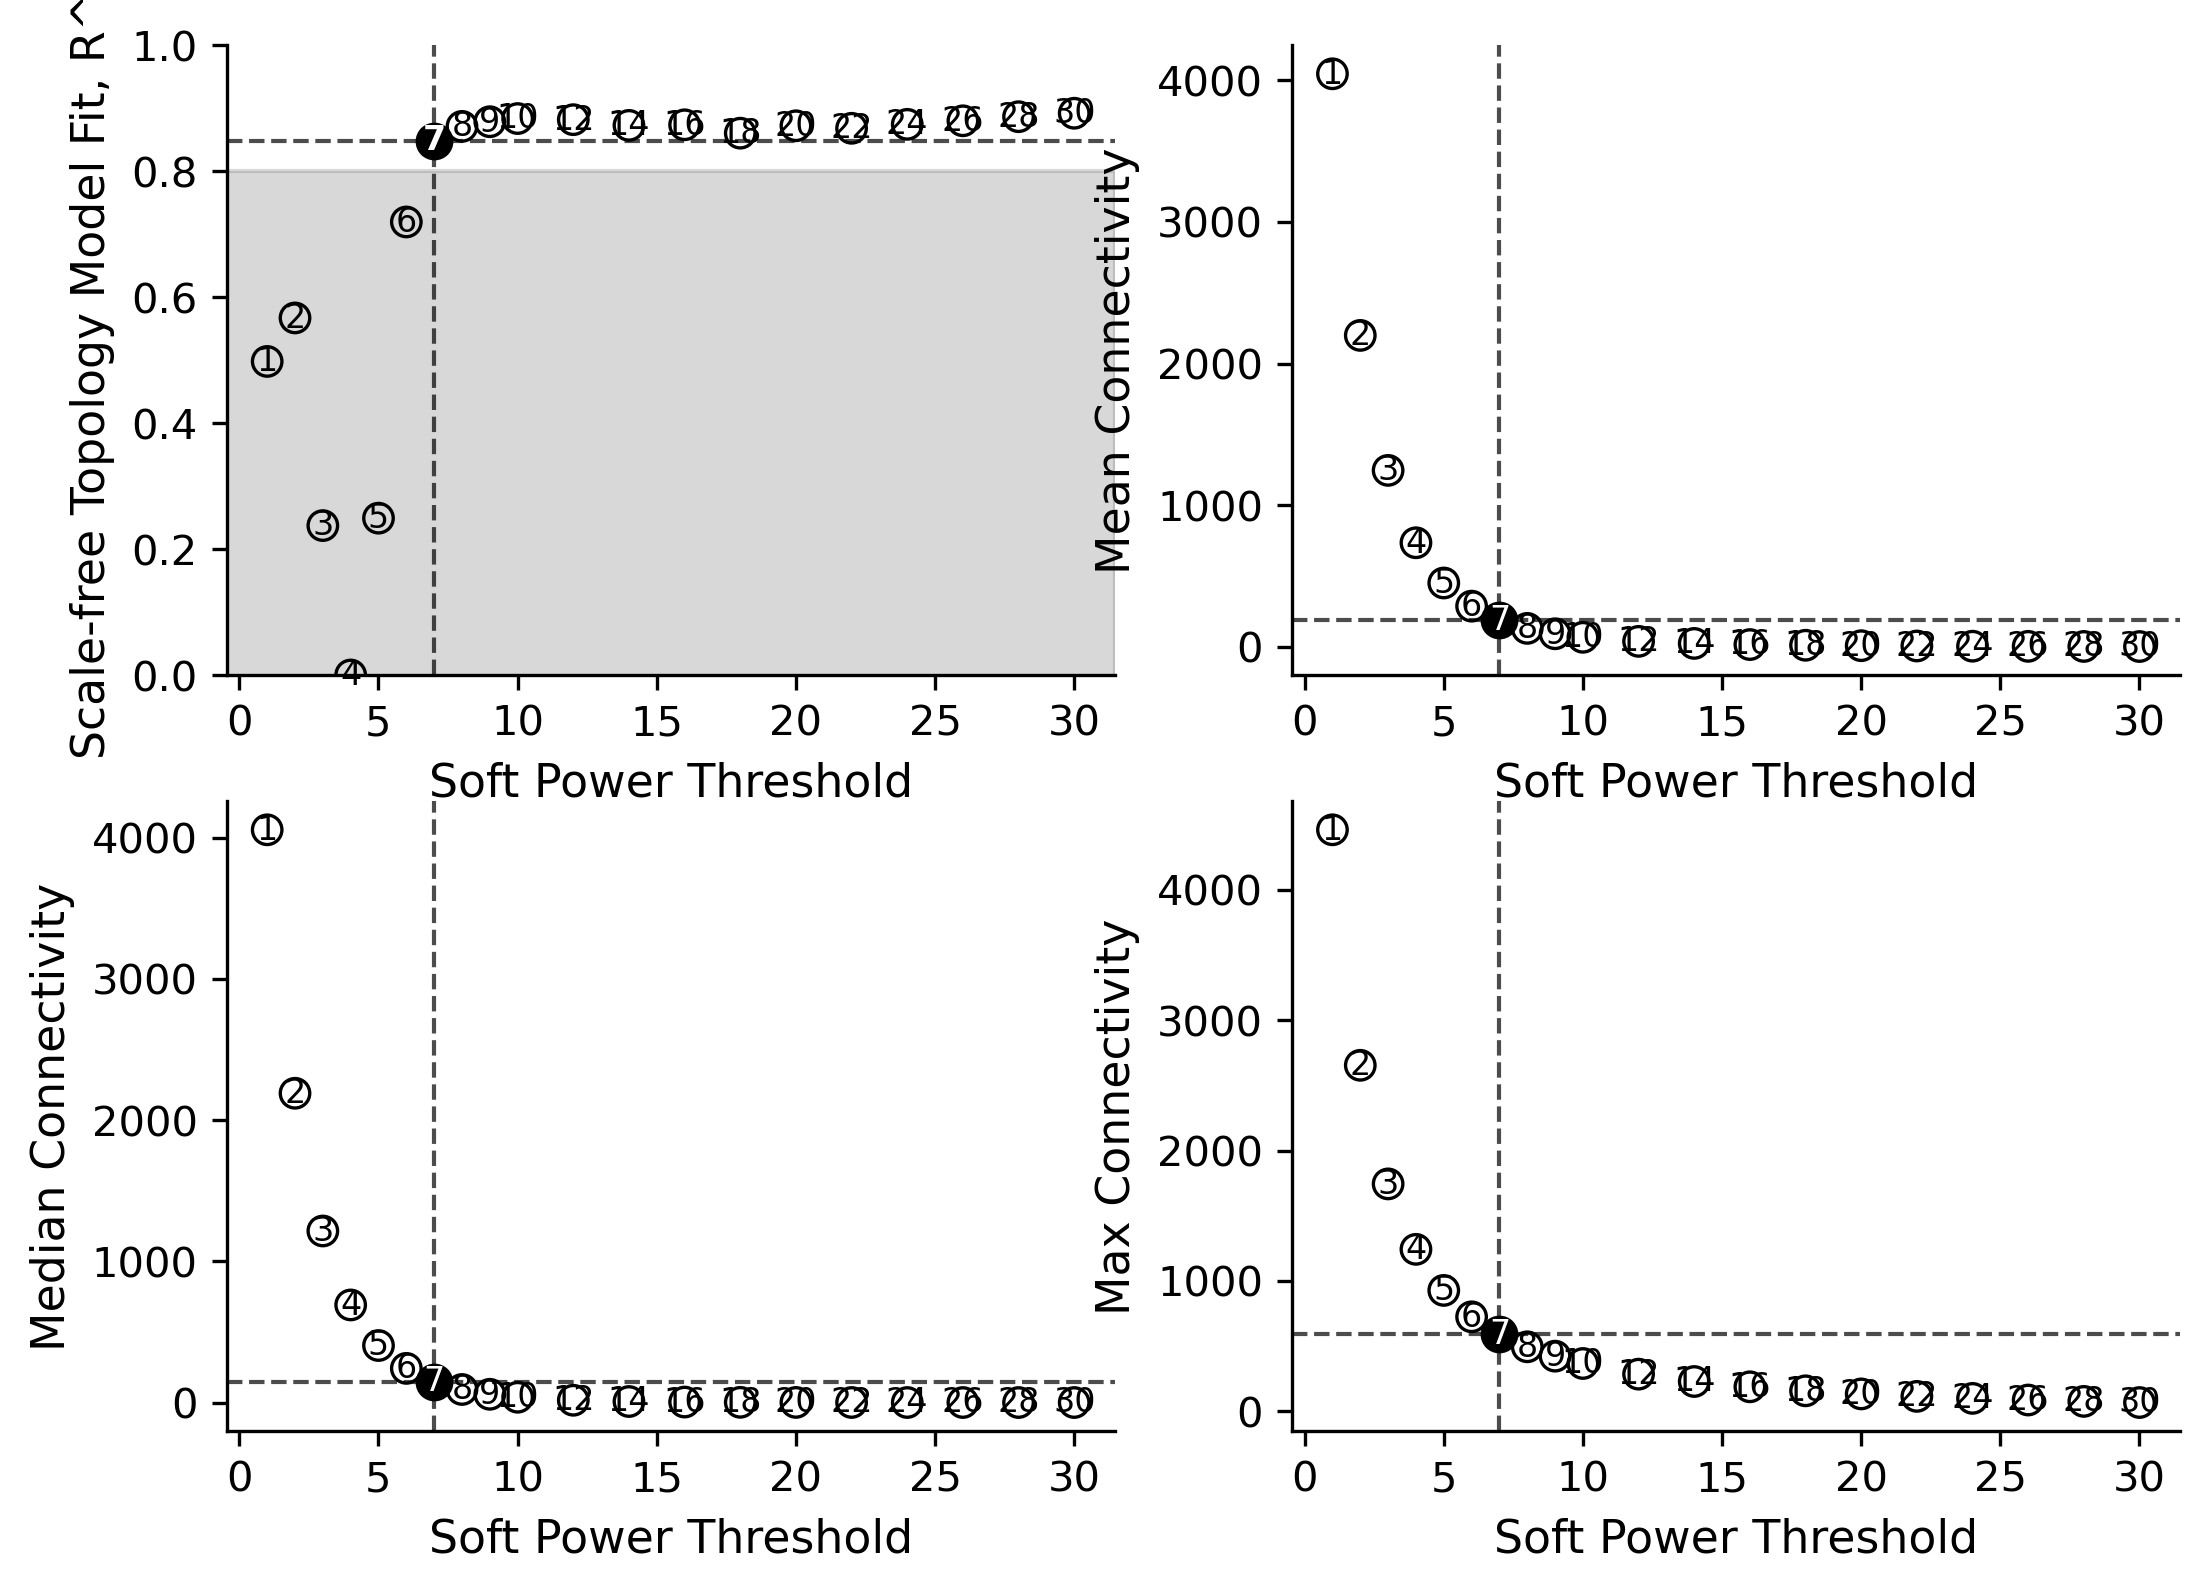

,Power,SFT.R.sq,slope,mean.k.
5,6,0.719370,-1.583187,287.742114
6,7,0.848621,-1.680041,190.495777
7,8,0.871080,-1.678682,130.668308
8,9,0.878491,-1.652691,92.633820


In [9]:
# Lowest power with SFT.R.sq >= r2_cutoff and slope < 0.
# The package prints its own choice above; this one replaces it.
selected_power = SelectWgcnaSoftPower(adata, r2_cutoff=r2_cutoff, wgcna_name=wgcna_name)
print(f'Selected power: {selected_power}')

fig01 = PlotWgcnaSoftPowers(adata, selected_power=selected_power, wgcna_name=wgcna_name)
plt.show()

# Powers around the selected one (the slope is not in the plots).
display(
    power_table.loc[
        power_table['Power'].between(selected_power - 1, selected_power + 2),
        ['Power', 'SFT.R.sq', 'slope', 'mean.k.']
    ]
)

### How to read the soft power plots

Each point is one tested power. The filled point and the vertical line show the
selected power.

- **Scale-free fit (top left):** R² of the fit of the connectivity distribution
  to the model used by WGCNA. Higher values mean a better fit, but they do not
  validate the network biologically. The grey area shows values below 0.80.
- **Mean connectivity (top right):** mean of the sum of link weights of each gene.
- **Median connectivity (bottom left):** central value of the gene connectivity.
- **Maximum connectivity (bottom right):** highest sum of link weights of one gene.

A higher power makes the link weights smaller, mostly the weak ones. So
connectivity goes down [Langfelder and Horvath, 2008].

The selected power is the lowest one with R² ≥ 0.80 and negative slope. The
slope is not shown in these plots; check it in the table.

The dashed horizontal lines show the value of each metric at the selected
power. They are not acceptance limits.

This step only chooses how to weight the links. It does not find modules or
hub genes yet.

# 6. Network and modules

`BuildWgcnaNetwork` computes the correlations between genes, applies the
selected power and computes the **topological overlap (TOM)**. Then it runs
hierarchical clustering and module detection, and it merges modules with very
similar eigengenes [Morabito et al., 2023].

In the dendrogram, each leaf is a gene. The height is the TOM dissimilarity:
branches that join at a lower height are more similar. The horizontal position
is only the order of the genes in the tree. It does not show groups or conditions.

The color bar shows the final modules. `grey` genes were not assigned to any
module. `grey` is not a co-expression program.

The number of modules and the shape of the tree, alone, do not validate the
network biologically.

| Parameter | Meaning |
|---|---|
| `power=selected_power` | Uses the soft power selected above. |
| `network_type=network_type` | Same type used in the power test (section 5). If you leave it out, the function reuses that type. A different type stops with an error. |
| `tom_type='signed'` | How the topological overlap treats the sign of the links. `signed` is the hdWGCNA default; keep it with signed networks. |
| `min_module_size=50` | Smallest module in the first module detection (hdWGCNA default); see below. |
| `deep_split=4` | High sensitivity to split branches into modules. **It is not the number of modules.** |
| `pam_stage=False` | Turns off an extra step that assigns more genes to modules. |
| `merge_cut_height=0.2` | Merges modules whose eigengenes have 1 - correlation below 0.2 (correlation ≥ 0.8). |
| `tom_name='hdWGCNA_TOM'` | Name of the TOM. |

#### Minimum module size: `min_module_size`

The default of `ConstructNetwork` in hdWGCNA is `minModuleSize = 50`.

| Value | Effect | When to use |
|---|---|---|
| 50 (default) | Only branches with at least 50 genes become modules. Fewer modules, usually more stable. | First analysis, or when the goal is broad programs. |
| 20 | Smaller branches also become modules. | When we expect small and specific programs, such as genes specific to one cell type or stage. |

With a value below 50, modules with fewer than 50 genes exist **only** because
of this choice. `FlagSmallWgcnaModules` lists them. Interpret them with more
care and, if possible, check them in a run with `min_module_size = 50`.

**Example dataset:** we use the default, **50**. The goal is broad programs
along maturation, and the metacells change a little between runs (see
section 3), so larger and more stable modules are safer.

Example with smaller modules:

```python
adata, module_sizes = BuildWgcnaNetwork(
    adata,
    power=selected_power,
    min_module_size=20,
    wgcna_name=wgcna_name,
)
# Modules with < 50 genes exist only because of min_module_size=20.
print(FlagSmallWgcnaModules(module_sizes, min_size=50))
```

Reference: [Morabito et al., 2023](https://doi.org/10.1016/j.crmeth.2023.100498).

In [10]:
adata, module_sizes = BuildWgcnaNetwork(
    adata,
    power=selected_power,
    network_type=network_type,  # must be the type used in the power test
    tom_type='signed',
    min_module_size=min_module_size,  # hdWGCNA default (50)
    deep_split=4,
    pam_stage=False,
    merge_cut_height=0.2,
    tom_name='hdWGCNA_TOM',
    wgcna_name=wgcna_name,
)
display(module_sizes.to_frame())

n_total = int(module_sizes.sum())
n_grey = int(module_sizes.get('grey', 0))
print(f'Genes in modules: {n_total - n_grey} of {n_total} ({(n_total - n_grey) / n_total:.1%})')
print(f'Genes in grey: {n_grey} ({n_grey / n_total:.1%})')

# Only matters when min_module_size < 50: these modules exist only because of it.
small_modules = FlagSmallWgcnaModules(module_sizes, min_size=50)
if small_modules.empty:
    print(f'Obs: every module has >= 50 genes (min_module_size={min_module_size}).')
else:
    print(
        'Obs: modules with < 50 genes. With the hdWGCNA default (min_module_size=50) '
        'they would probably not be detected. Interpret them with care:'
    )
    print(small_modules.to_string())

ConstructNetwork: building co-expression network with power=7, 7794 genes, 3865 samples
Computing correlation matrix (pearson)...
  Cor matrix shape: (7794, 7794), range=[-0.9521, 1.0000]
Applying soft-thresholding...
  Adj matrix shape: (7794, 7794), range=[0.000000, 1.000000]
Computing Topological Overlap Matrix (TOM)...
  TOM dissim shape: (7794, 7794), range=[0.0000, 0.9994]
Performing hierarchical clustering + dynamic tree cutting in R...
Identified 10 modules (6002 unassigned/grey)
Merging similar modules...
  Merge step: n_modules=9, cut_height=0.2
  ME correlation range: [-0.9217, 1.0000]
  ME dissimilarity range: [0.0924, 1.9217]
    Module 1 vs Module 2: cor=0.8291, dissim=0.1709
    Module 1 vs Module 3: cor=0.3239, dissim=0.6761
    Module 1 vs Module 4: cor=0.7378, dissim=0.2622
    Module 1 vs Module 5: cor=-0.5817, dissim=1.5817
    Module 1 vs Module 6: cor=-0.7052, dissim=1.7052
    Module 1 vs Module 7: cor=0.9076, dissim=0.0924
    Module 1 vs Module 8: cor=-0.3870, 

,n_genes
module,
grey,6002
M2,506
M1,429
M3,371
M5,249
M4,183
M9,54


Genes in modules: 1792 of 7794 (23.0%)
Genes in grey: 6002 (77.0%)
Obs: every module has >= 50 genes (min_module_size=50).


  No linkage_matrix found, computing from TOM dissimilarity...
  Linkage matrix computed: shape=(7793, 4)


/home/tahila/miniconda3/envs/scRNA_NEW_signaling_py311/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


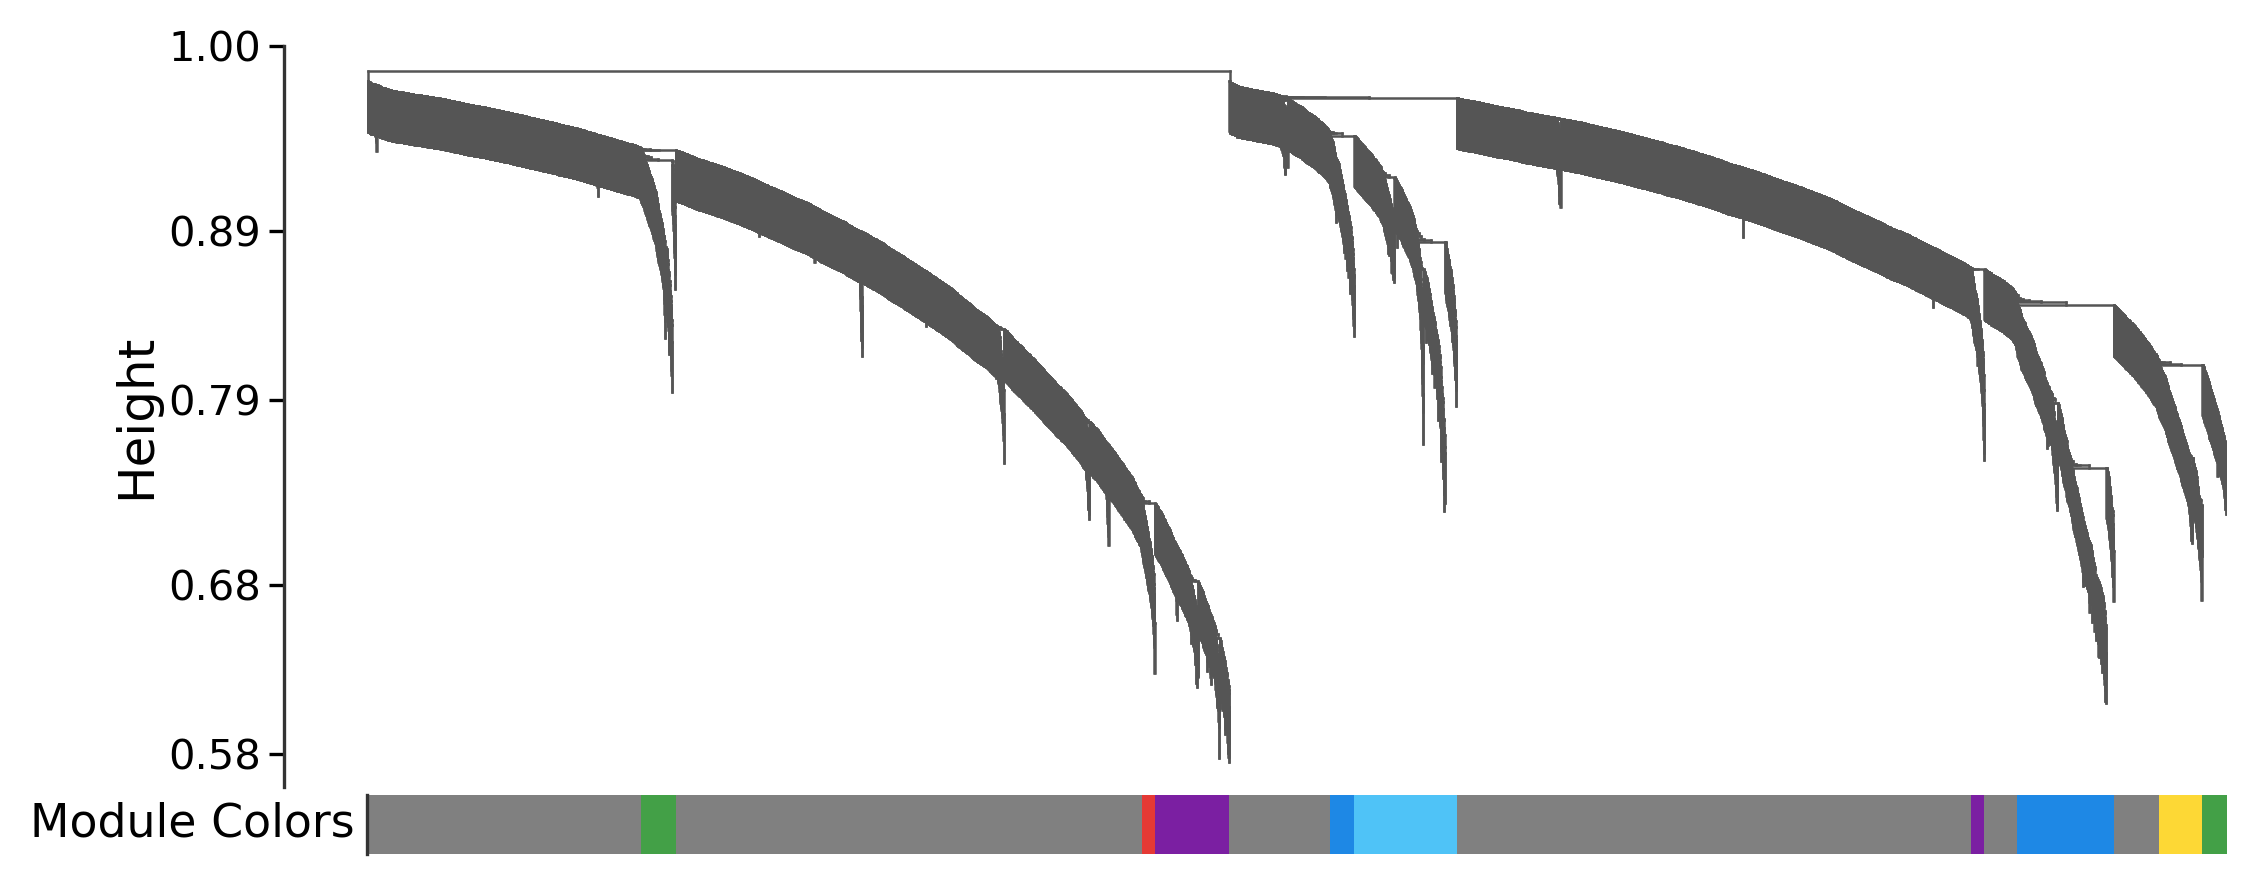

In [11]:
fig02 = PlotWgcnaDendrogram(adata, wgcna_name=wgcna_name)
plt.show()

# 7. Module eigengenes

We found the modules in the metacells. Now we compute their eigengenes in the
single cells.

The eigengene is the first principal component of the expression of the module
genes. It summarizes the main pattern of variation of these genes, with one
value per cell [Morabito et al., 2023].

We use `QC_filtered_log1p`, the normalized expression of the same counts used
to build the network. The modules found above are kept.

#### Eigengenes with or without Harmony

hdWGCNA can correct the eigengenes with Harmony (`harmonize=True`). The result
is the harmonized eigengenes (`hMEs`). The documentation suggests this
correction for technical effects, such as sequencing batch or dataset of
origin. Harmony reduces the differences between the groups given in
`group_by_vars`.

| Situation | Option | Why |
|---|---|---|
| The factor to correct is technical and is **not** the same as the condition (e.g. sequencing batches that contain samples of all conditions). | `harmonize=True`, `group_by_vars='batch'` | Removes the technical effect and keeps the difference between conditions. |
| Each sample belongs to one condition only, and the goal is to compare conditions. | `harmonize=False` | Correcting by sample would also remove part of the difference between conditions. |
| Only visualization, or comparison between groups, without comparing conditions. | Either | Harmony by sample can smooth sample differences in the plots. |

**Example dataset:** there is one sample per condition (49 = SPF, 50 = GF), so
sample and condition are the same factor. Harmony by sample would remove the
GF vs SPF difference completely. So we use **`harmonize=False`**, and the
eigengenes are stored in `MEs`.

Example with Harmony, for data where the corrected factor is technical and is
not the same as the condition:

```python
adata, hmes = ComputeWgcnaEigengenes(
    adata,
    layer=expression_layer,
    harmonize=True,
    group_by_vars='batch',  # technical factor, not nested in the condition
    wgcna_name=wgcna_name,
)
```

**Comparison between conditions:** the statistical unit is the sample, not the
cell or the metacell. Summarize the eigengenes per sample inside each group
(for example, the mean) before the test [Zimmerman et al., 2021; Squair et al., 2021].
With few samples per condition, this comparison is mostly descriptive. With one
sample per condition, as in the example dataset, no test is valid (see the
caveat in the introduction).

References:

- [Morabito et al., 2023](https://doi.org/10.1016/j.crmeth.2023.100498).
- [Zimmerman et al., 2021](https://doi.org/10.1038/s41467-021-21038-1).
- [Squair et al., 2021: Confronting false discoveries in single-cell
  differential expression](https://doi.org/10.1038/s41467-021-25960-2).

Computing module eigengenes (Seurat-compatible ScaleData + SVD PCA + Harmony)...
ModuleEigengenes complete: 6 module eigengenes for 10511 cells
Module eigengenes: 10511 cells x 6 modules


,M5,M4,M1,M2,M3,M9
AAACCCAAGAAGCCTG-1-49,24.374141,33.755613,2.351283,16.901328,-15.526908,-7.191094
AAACCCAAGTCAATCC-1-49,2.006142,-3.501290,3.045435,-5.560744,-6.352453,-3.535195
AAACCCAAGTCATGCT-1-49,1.586685,-1.758712,7.508338,-0.690320,-8.198696,-1.893982
AAACCCAGTGAGTCAG-1-49,-2.795805,-3.424614,10.206578,-4.952932,-3.805491,-0.000363
AAACCCAGTTCCCACT-1-49,-8.315617,-3.892447,-11.301500,-6.386369,3.670495,4.220319


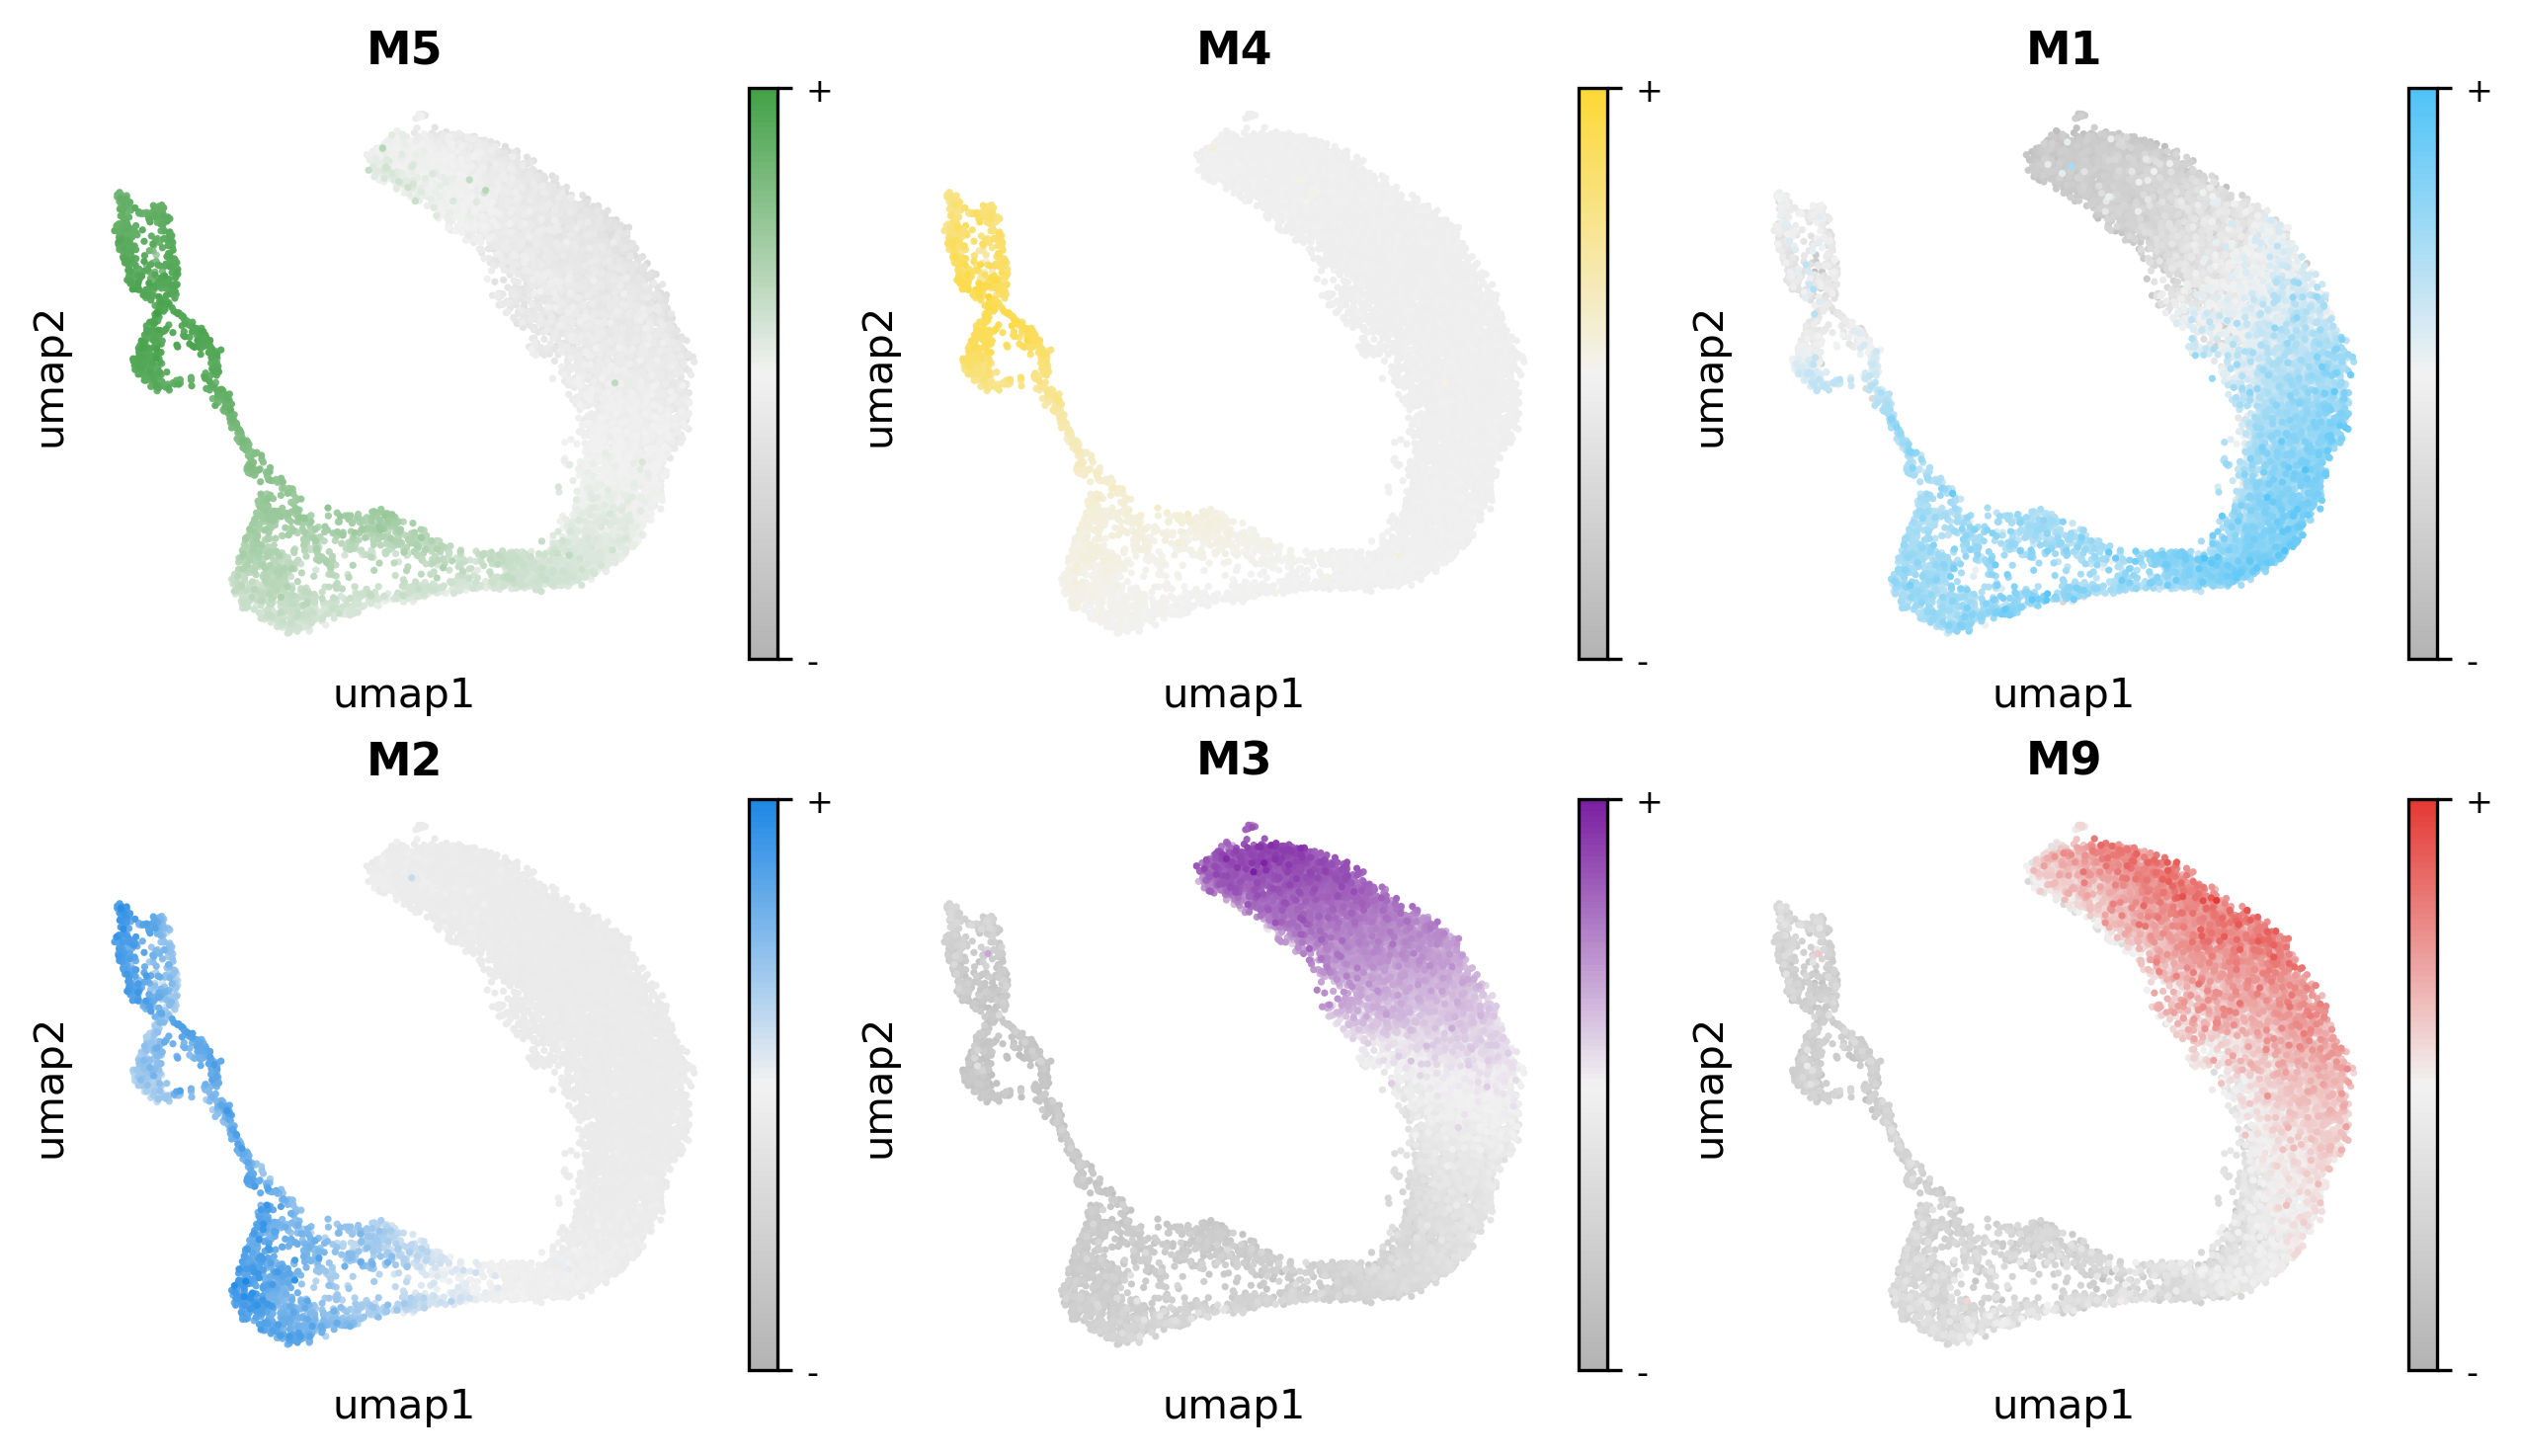

In [12]:
# No Harmony: one sample per condition, so sample = condition (see the markdown above).
adata, mes = ComputeWgcnaEigengenes(
    adata,
    layer=expression_layer,
    harmonize=False,
    wgcna_name=wgcna_name,
)
print(f'Module eigengenes: {mes.shape[0]} cells x {mes.shape[1]} modules')
display(mes.head())

fig03 = PlotWgcnaModuleFeatures(
    adata,
    features='MEs',
    reduction=plot_reduction,
    ncols=3,
    wgcna_name=wgcna_name,
)
plt.show()

### Eigengenes on the UMAP

Each cell gets one value per module. This value is a weighted combination of
the gene expression, not a simple mean. Negative values do not mean negative
expression. The grey color in the plots is not the `grey` gene group of the
dendrogram.

In the UMAPs, each point is a cell and each panel is a module. Compare them
with the annotated UMAP below to see which groups (cell types, stages) each
module marks. These associations are descriptive. The biological function of
the modules comes from their genes and from the enrichment analysis.
Comparisons between conditions are done separately inside each group.

Reference: [Morabito et al., 2023](https://doi.org/10.1016/j.crmeth.2023.100498).

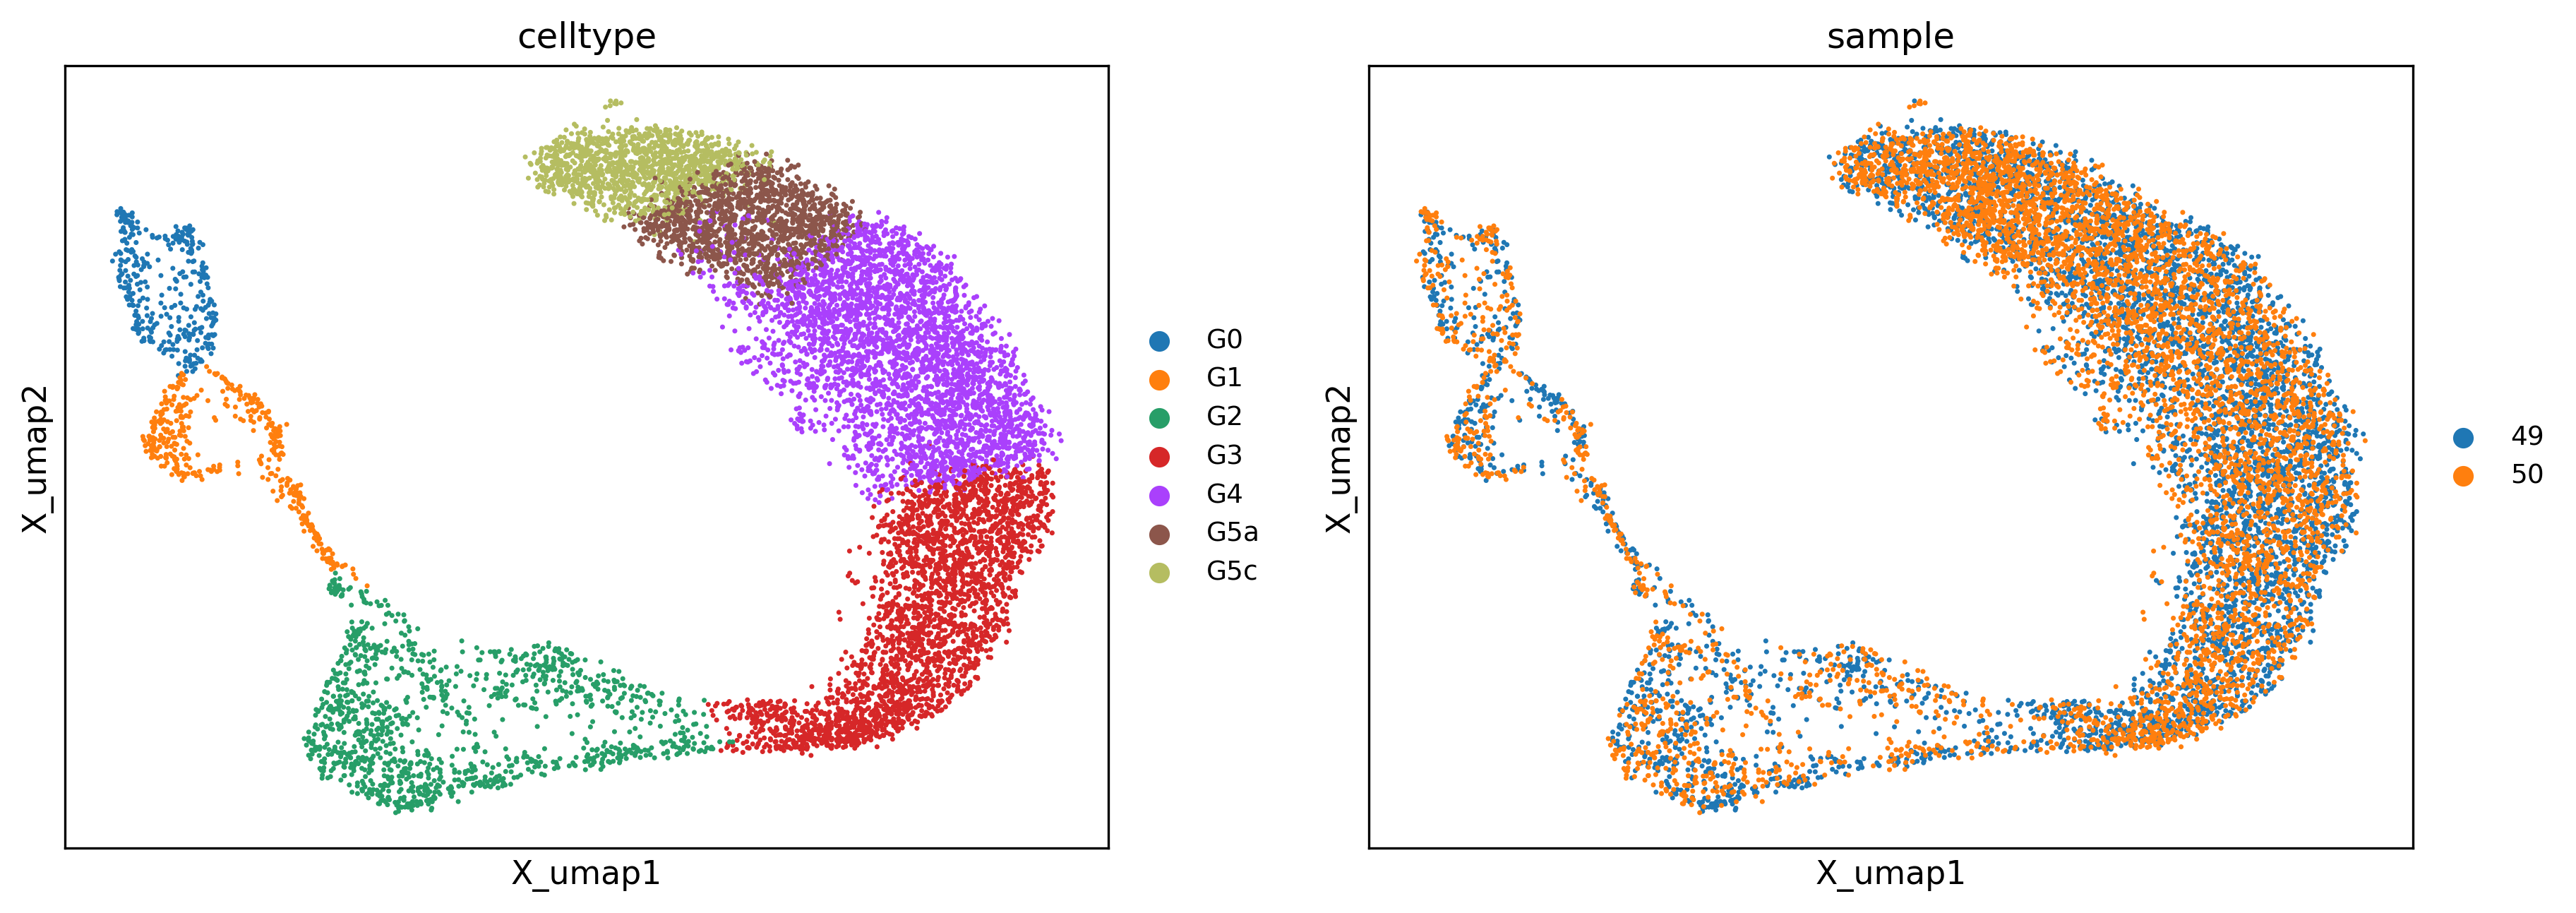

In [13]:
# Same embedding as the eigengene plots above.
sc.pl.embedding(
    adata,
    basis=plot_reduction,
    color=[celltype_col, sample_col],
    ncols=2,
)

# 8. Gene-module connectivity: kME

kME is the correlation between the expression of a gene and the eigengene of a
module [Morabito et al., 2023].

- **Close to +1:** the gene follows the module pattern closely.
- **Close to 0:** little linear relation with the pattern.
- **Close to -1:** the gene changes in the opposite direction.

We compute kME in the single cells of the groups used in the network, with
the eigengenes without Harmony (`MEs`).

**Domain note:** in the Python port, `module_connectivity` always reads
`hMEs`. With `harmonize=False`, the package stores a copy of `MEs` in `hMEs`, so
kME uses the uncorrected eigengenes. If you run `ComputeWgcnaEigengenes` with
Harmony, kME uses the harmonized ones.

#### Sparse or dense computation

`ComputeWgcnaKme` has two ways to compute the correlation:

| Option | Methods | Memory and speed | When to use |
|---|---|---|---|
| `sparse=True` (default) | Pearson only | Works on the sparse matrix. Fast, low memory. Same as the R default (`corSparse`). | When the network uses Pearson. |
| `sparse=False` | `pearson`, `bicor` or `spearman` | Builds a dense cells x genes matrix. Slower, much more memory. | When the network uses another method (e.g. bicor) and you want kME with the same method. |

**Domain note:** in the Python port, `sparse=True` ignores `cor_method` and
always uses Pearson. `ComputeWgcnaKme` stops with an error if you ask for
`sparse=True` with another method, so the result is never different from
what you asked for.

Single cells have even more zeros than metacells. So the MAD = 0 problem of
bicor (section 4) is stronger here.

**Example dataset:** the network uses Pearson, so we use `sparse=True` and
`cor_method='pearson'`.

Example with bicor, for a network built with bicor:

```python
adata, modules_df = ComputeWgcnaKme(
    adata,
    group_by=celltype_col,
    groups=network_stages,
    layer=expression_layer,
    cor_method='bicor',
    sparse=False,  # needed for bicor; uses much more memory
    wgcna_name=wgcna_name,
)
```

Inside each module, genes are ranked by their kME. The genes with the highest
values are hub candidates. They represent the co-expression pattern well. They
are not necessarily causal regulators, and not necessarily differentially
expressed between conditions.

Reference: [Morabito et al., 2023](https://doi.org/10.1016/j.crmeth.2023.100498).

Computing kME (eigengene-based connectivity)...
ModuleConnectivity complete: kME computed for 6 modules


,gene_name,module,color,kME_M5,kME_M4,kME_M1,kME_M2,kME_M3,kME_M9
0,Mrpl15,M5,#43A047,0.586700,0.559102,0.164859,0.498472,-0.422764,-0.441967
7,Rrs1,M4,#FDD835,0.544545,0.642916,0.025841,0.428604,-0.307893,-0.332462
11,Ppp1r42,M1,#4FC3F7,-0.040931,-0.100231,0.260752,-0.043438,-0.152080,-0.057147
12,Gm57177,M1,#4FC3F7,-0.031035,-0.067978,0.180169,-0.023896,-0.091488,-0.023258
16,Cpa6,M1,#4FC3F7,0.119592,-0.051925,0.507503,0.115569,-0.385672,-0.275862


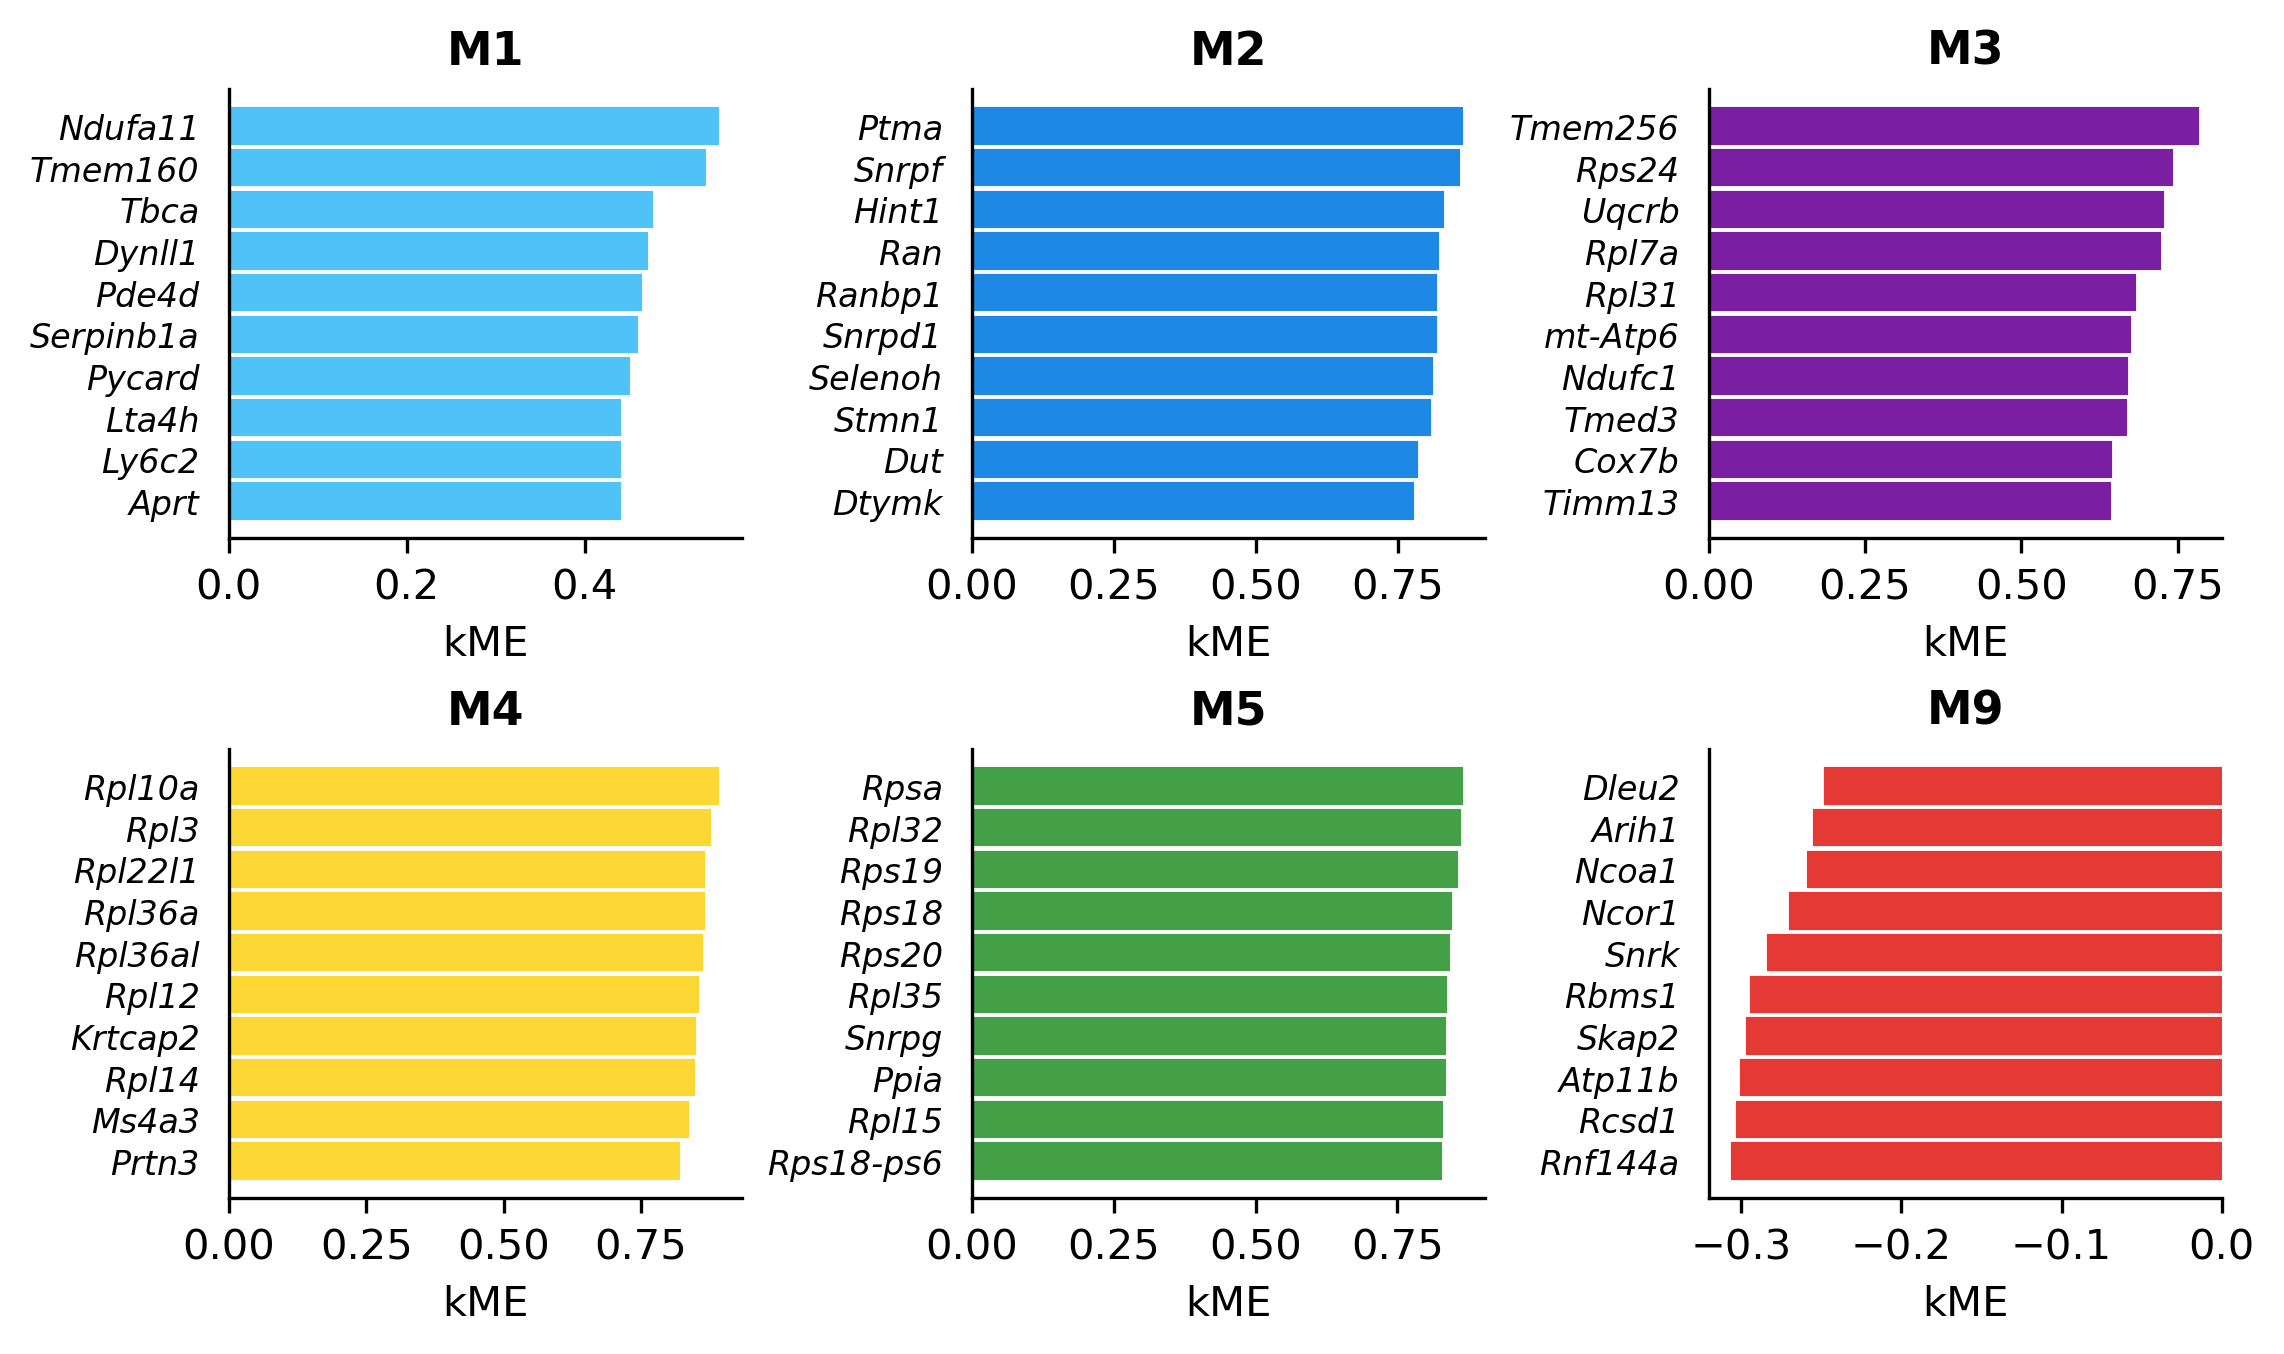

,gene_name,module,kME
0,Rpsa,M5,0.861217
1,Rpl32,M5,0.858909
2,Rps19,M5,0.852377
3,Rps18,M5,0.842037
4,Rps20,M5,0.839534
5,Rpl35,M5,0.833580
6,Snrpg,M5,0.832316
7,Ppia,M5,0.831185
8,Rpl15,M5,0.827378
9,Rps18-ps6,M5,0.824103


In [14]:
adata, modules_df = ComputeWgcnaKme(
    adata,
    group_by=celltype_col,
    groups=network_stages,
    layer=expression_layer,
    cor_method='pearson',  # same method as the network
    sparse=True,           # fast; Pearson only
    wgcna_name=wgcna_name,
)
display(modules_df.loc[modules_df['module'] != 'grey'].head())

fig04 = PlotWgcnaKmes(
    adata,
    n_hubs=10,
    ncols=3,
    text_size=8,
    wgcna_name=wgcna_name,
)
plt.show()

hub_genes = GetWgcnaHubGenes(adata, n_hubs=10, wgcna_name=wgcna_name)
display(hub_genes)

# 9. Functional enrichment of the modules

Over-representation analysis (ORA) tests which gene sets appear more often in
the list of a module than expected from the reference universe.

As in the hdWGCNA enrichment tutorial, we use up to 100 genes per module,
ranked by the kME of the module. We use three collections:

- **GO Biological Process:** biological processes.
- **GO Molecular Function:** molecular functions.
- **MSigDB Hallmark:** 50 well-defined biological states and processes,
  each one summarizing many overlapping gene sets [Liberzon et al., 2015].

The **Cellular Component** collection (cell components and locations), used in
the hdWGCNA tutorial, is not included in this analysis.

**Python adaptation:** we use GSEApy to query the Enrichr service, instead of
the function of the Python port [Fang et al., 2023].

#### Reference universe (background)

The test compares the frequency of the genes of a term in the module with the
frequency of this term in the reference universe. The choice of universe
changes the result:

| Universe | What it is | When to use |
|---|---|---|
| Enrichr default | All genes of the library. | When the gene list comes from the whole genome, without a previous filter. |
| Network genes (`background='network'`) | The genes that could enter a module. | When the list comes from a filtered gene set, as in this workflow. |

Here, modules can only contain network genes: genes detected in at least 5% of
the cells. With the default universe, general terms of the cell type would look
enriched only because all tested genes are expressed in that cell type (in the
example dataset, general neutrophil and immune terms). So we use **the network
genes as universe** [Timmons et al., 2015; Wijesooriya et al., 2022].

Example with the Enrichr default universe:

```python
enrichment_df = RunWgcnaEnrichr(
    adata,
    databases=databases,
    background=None,
    wgcna_name=wgcna_name,
)
```

**Organism:** `RunWgcnaEnrichr` has no default organism; you must choose it
when you call the function (e.g. `'human'`, `'mouse'`, `'fly'`, `'yeast'`,
`'worm'`, `'fish'`).

**Domain note:** in GSEApy, `'human'` and `'mouse'` use the same Enrichr site
and the same libraries, with human gene symbols. For mouse data, the symbols
are matched without case, so most genes map, but mouse-only genes (e.g. `Rik`
genes) are lost. Other organisms (fly, yeast, worm, fish) use their own sites
and libraries.

**Domain note:** with `background`, GSEApy uses another Enrichr service
(speedrichr). The result table has no `Overlap` column. The number of genes of
each term is counted from the `Genes` column.

**Domain note:** Hallmark has only 50 sets, so the multiple-testing correction
is much lighter than for GO.

Adjusted p-values are corrected inside each module and collection. We use
`Adjusted P-value < 0.05` as an exploratory cutoff.

Enrichment helps to interpret the modules. It does not show pathway activation
or differences between conditions. Look at the genes behind each term.

References:

- [Fang et al., 2023](https://doi.org/10.1093/bioinformatics/btac757).
- [Liberzon et al., 2015: The Molecular Signatures Database Hallmark Gene
  Set Collection](https://doi.org/10.1016/j.cels.2015.12.004).
- [Timmons et al., 2015: Multiple sources of bias confound functional
  enrichment analysis of global -omics data](https://doi.org/10.1186/s13059-015-0761-7).
- [Wijesooriya et al., 2022: Urgent need for consistent standards in
  functional enrichment analysis](https://doi.org/10.1371/journal.pcbi.1009935).

In [ ]:
#### ATTENTION!!! THIS SPECIFIC CODE SHOW ENRICHMENT ONLY WITH TOP 100 GENES!


enrichment_df = RunWgcnaEnrichr(
    adata,
    databases=databases,
    organism='mouse',  # required; the example dataset is mouse
    n_genes=100,
    background='network',
    wgcna_name=wgcna_name,
)
print(enrichment_df.groupby('module')['n_module_genes'].first().to_string())
display(enrichment_df.head())

enrichment_sig = SelectSignificantEnrichment(enrichment_df, padj_cutoff=0.05)
display(
    enrichment_sig
    .groupby(['module', 'Gene_set'], sort=False)
    .head(5)[['module', 'Gene_set', 'Term', 'Adjusted P-value', 'Genes']]
)

module
M1    100
M2    100
M3    100
M4    100
M5    100
M9     54


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes,module,n_module_genes
0,GO_Biological_Process_2023,Regulation Of Cell Communication By Electrical...,0.000020,0.016597,0,0,118.948454,1286.298503,PDE4D;SRI;CALM1,M1,100
1,GO_Biological_Process_2023,Regulation Of Release Of Sequestered Calcium I...,0.000069,0.028506,0,0,59.458763,569.607747,PDE4D;SRI;CALM1,M1,100
2,GO_Biological_Process_2023,Regulation Of Ryanodine-Sensitive Calcium-Rele...,0.000163,0.044764,0,0,39.628866,345.687399,PDE4D;SRI;CALM1,M1,100
3,GO_Biological_Process_2023,Mucosal Immune Response (GO:0002385),0.000230,0.047515,0,0,33.963181,284.468644,FFAR2;CAMP;LTF,M1,100
4,GO_Biological_Process_2023,Positive Regulation Of Cytokine Production (GO...,0.000355,0.058561,0,0,5.099427,40.507977,C3;ANXA1;PDE4D;S100A13;FFAR2;AGPAT2;GAPDH;SPTBN1,M1,100


,module,Gene_set,Term,Adjusted P-value,Genes
0,M1,GO_Biological_Process_2023,Regulation Of Cell Communication By Electrical...,1.659702e-02,PDE4D;SRI;CALM1
1,M1,GO_Biological_Process_2023,Regulation Of Release Of Sequestered Calcium I...,2.850594e-02,PDE4D;SRI;CALM1
2,M1,GO_Biological_Process_2023,Regulation Of Ryanodine-Sensitive Calcium-Rele...,4.476404e-02,PDE4D;SRI;CALM1
3,M1,GO_Biological_Process_2023,Mucosal Immune Response (GO:0002385),4.751518e-02,FFAR2;CAMP;LTF
825,M1,GO_Molecular_Function_2023,Calcium Ion Binding (GO:0005509),3.437815e-03,PLSCR1;ANXA1;GCA;ANXA3;S100A13;SRI;AOAH;CALM1
987,M1,MSigDB_Hallmark_2020,Complement,7.603777e-03,C3;PLSCR1;GCA;S100A13;LTA4H;CALM1;LTF
988,M1,MSigDB_Hallmark_2020,Hypoxia,1.734714e-02,ERO1A;PRDX5;LDHA;CITED2;GAPDH;ETS1
989,M1,MSigDB_Hallmark_2020,Coagulation,1.734714e-02,C3;ANXA1;S100A13;LTA4H
1022,M2,GO_Biological_Process_2023,Microtubule Cytoskeleton Organization Involved...,1.306595e-11,NUDC;CDCA8;KIF11;AURKB;NDC80;CENPE;STMN1;NUSAP...
1023,M2,GO_Biological_Process_2023,Mitotic Spindle Organization (GO:0007052),1.158505e-08,CENPE;TPX2;NUDC;PRC1;STMN1;BIRC5;CDCA8;KIF11;A...


### Dot plot of the top terms

For each collection, the plot shows the top 5 terms of each module. A term is
shown in every module where it is significant. Color is -log10(adjusted p-value),
and size is the number of module genes in the term.

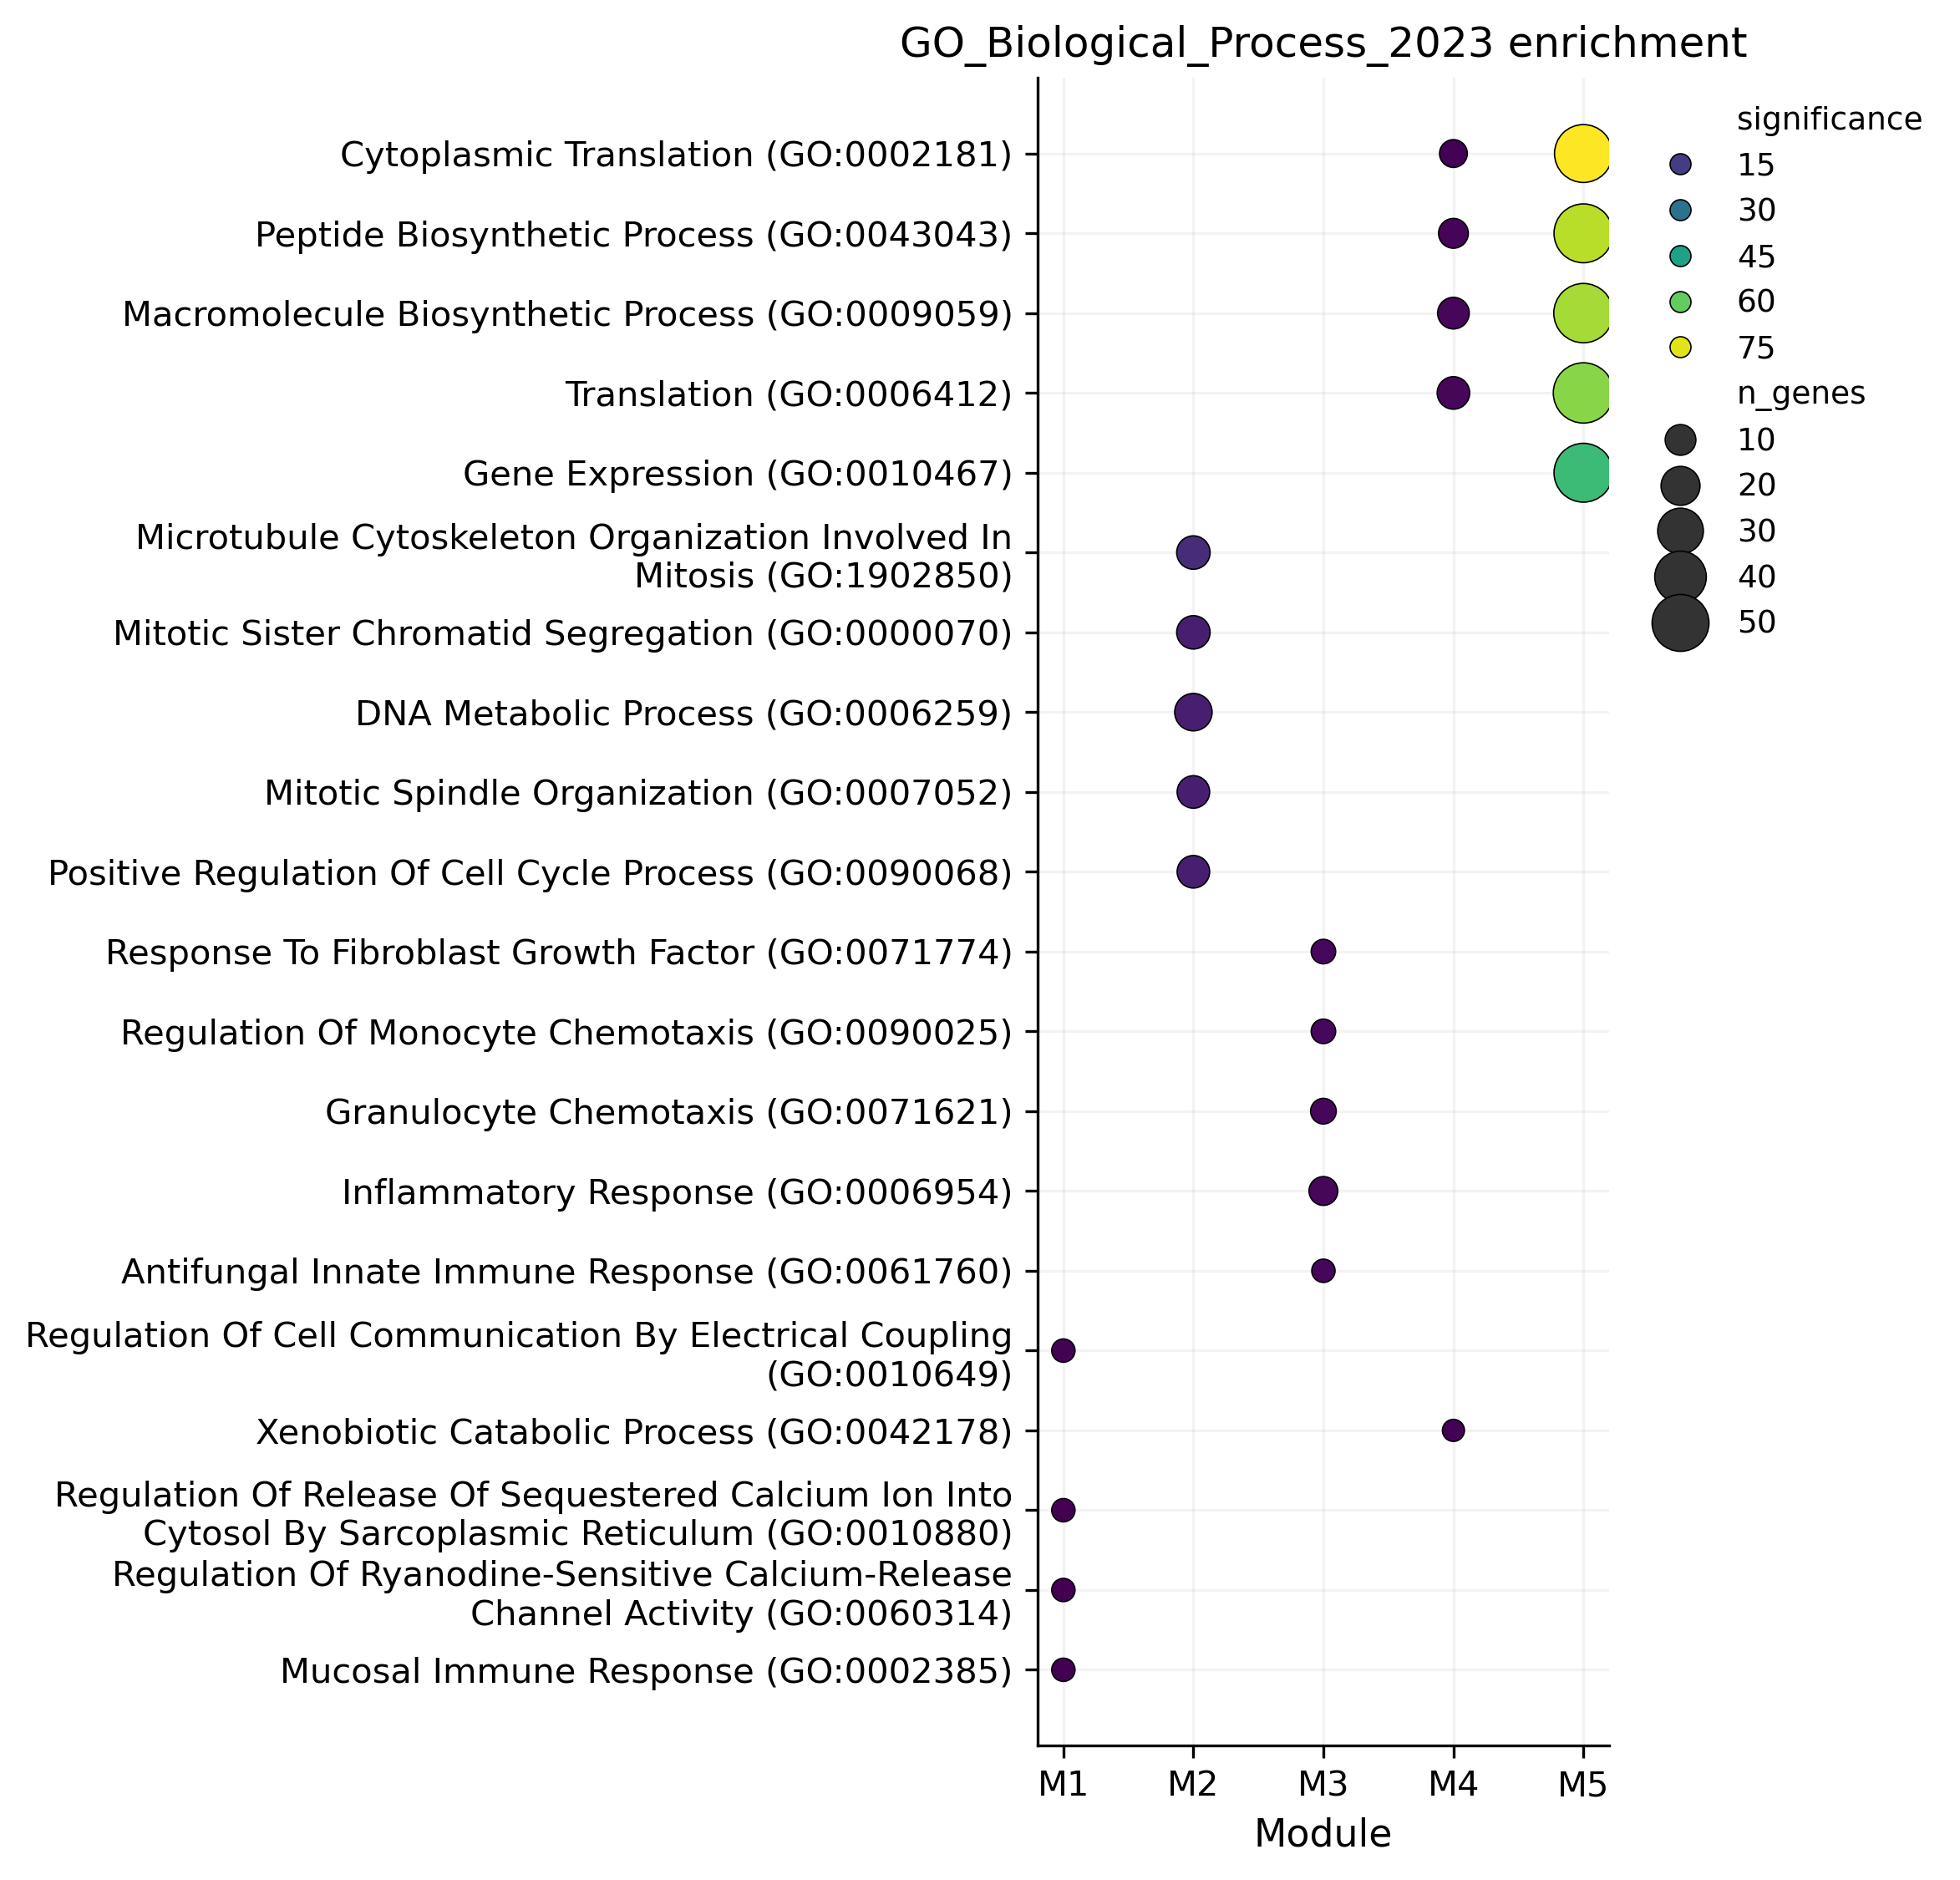

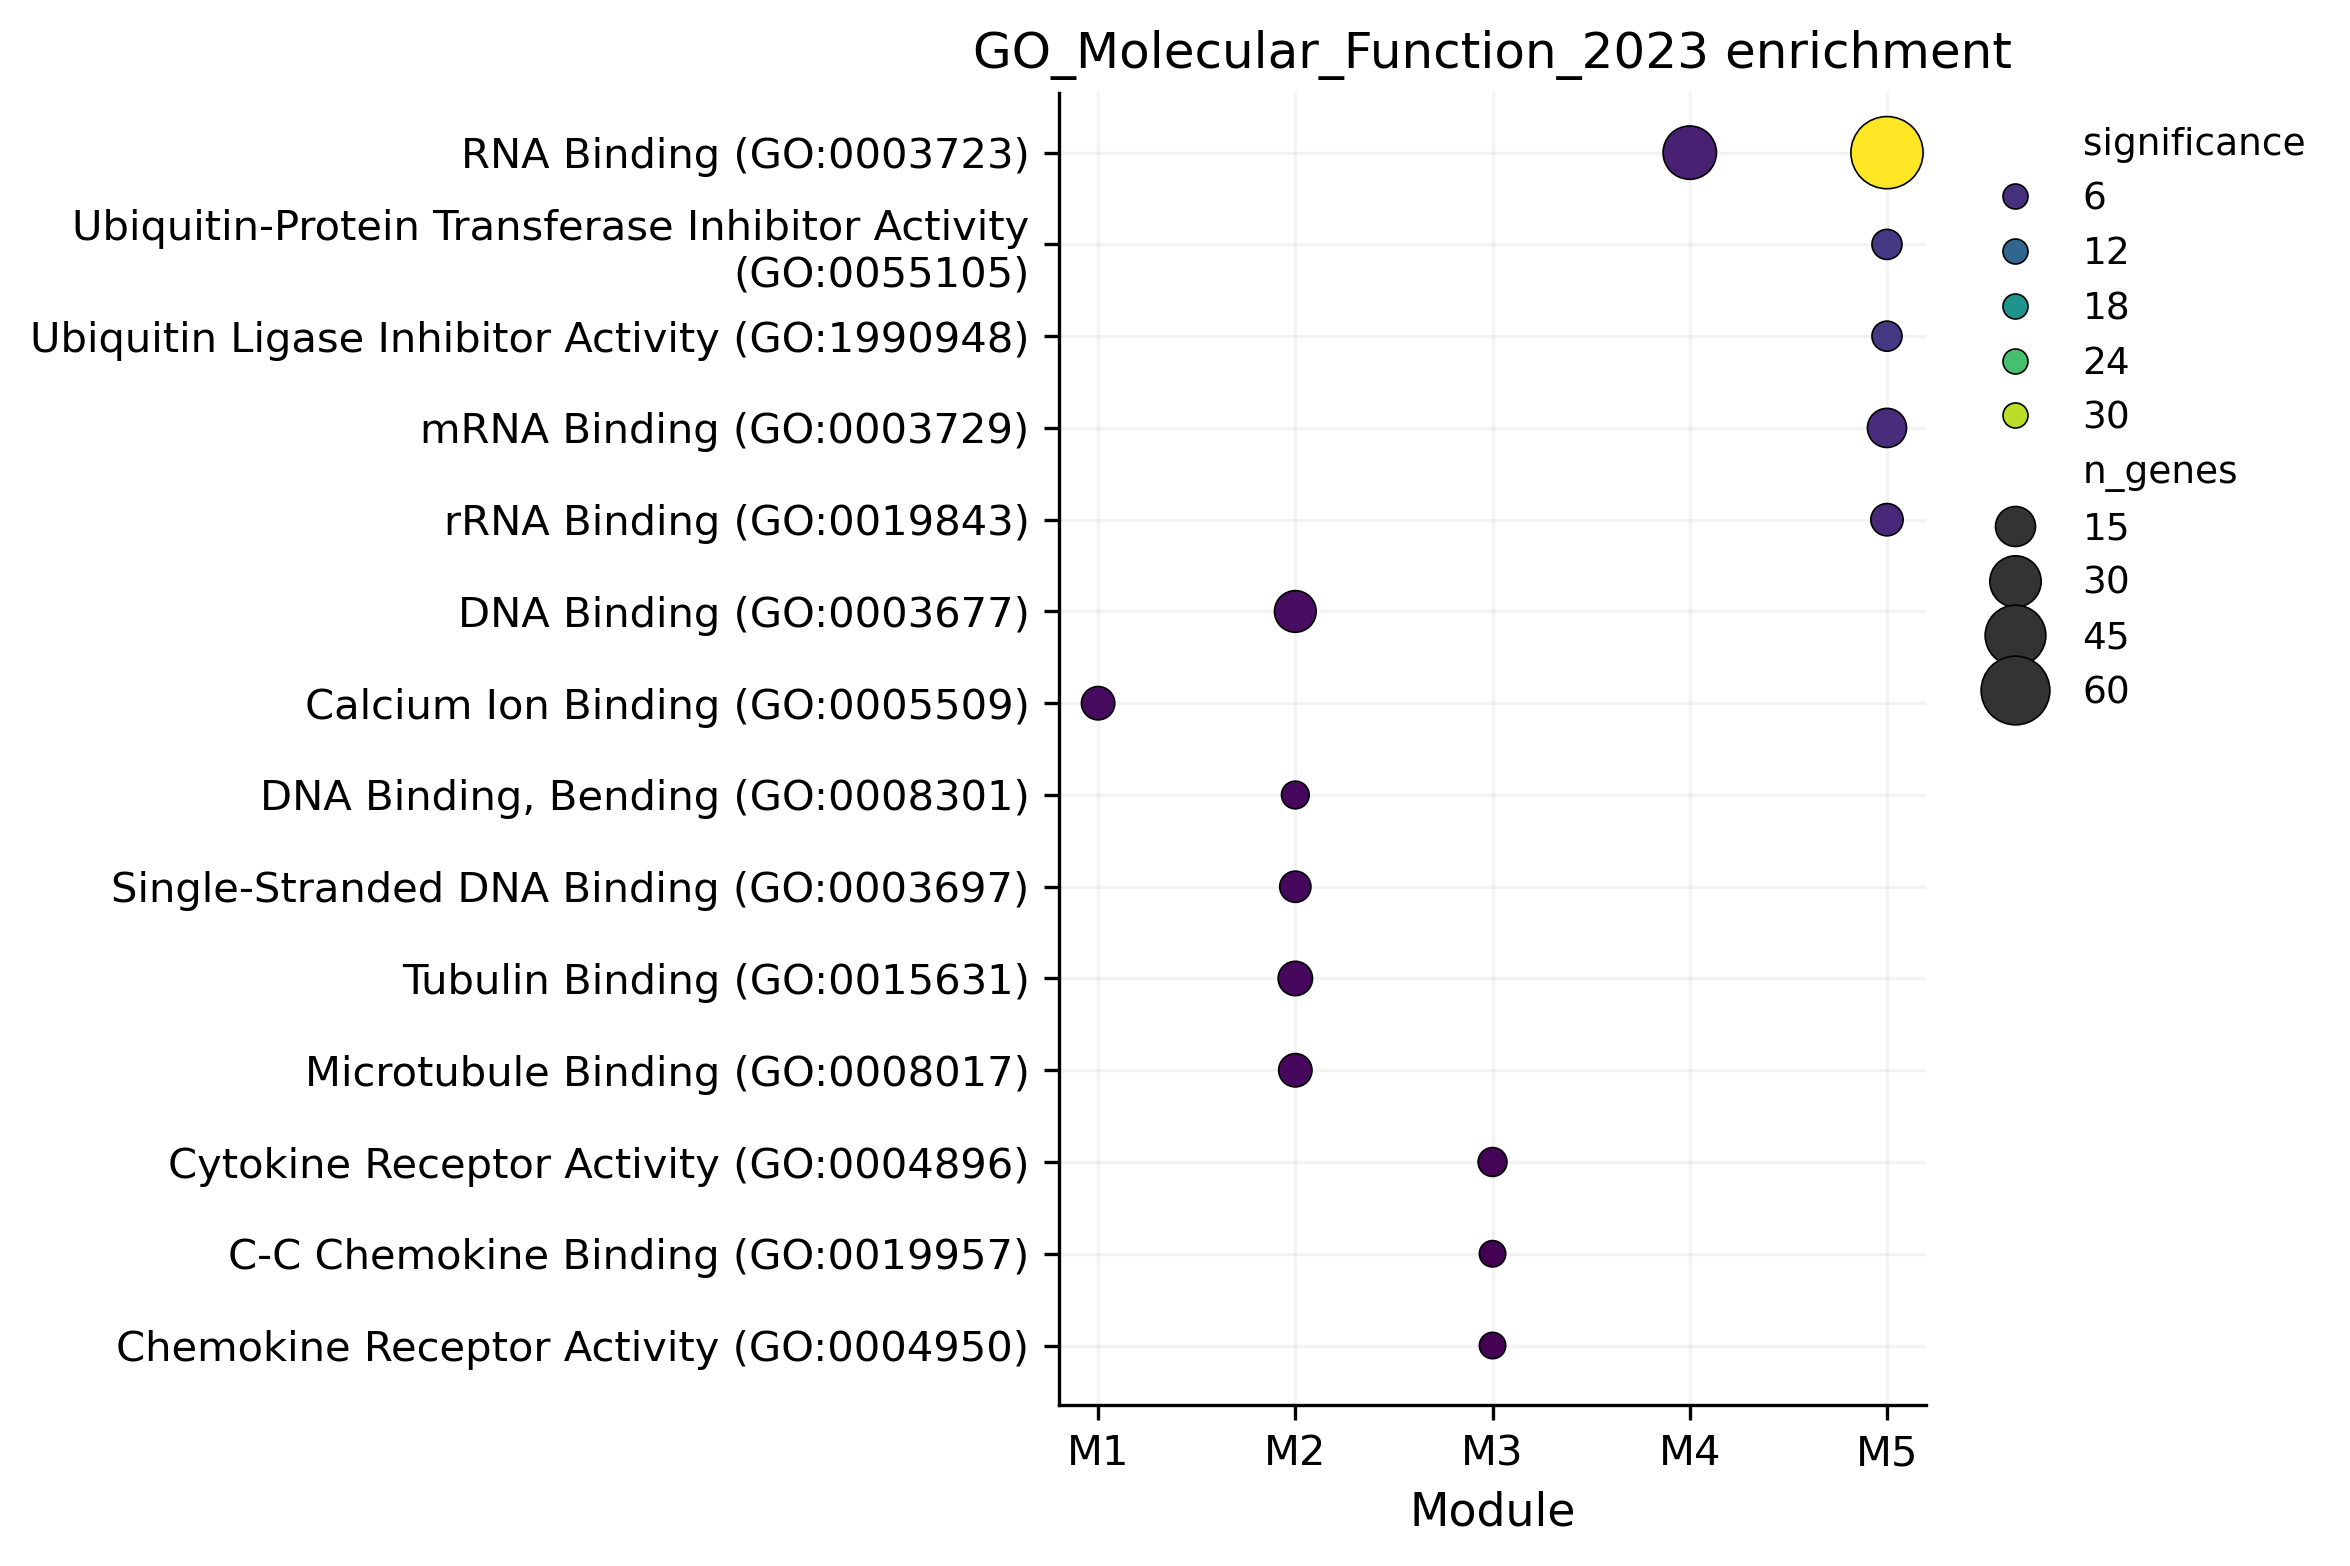

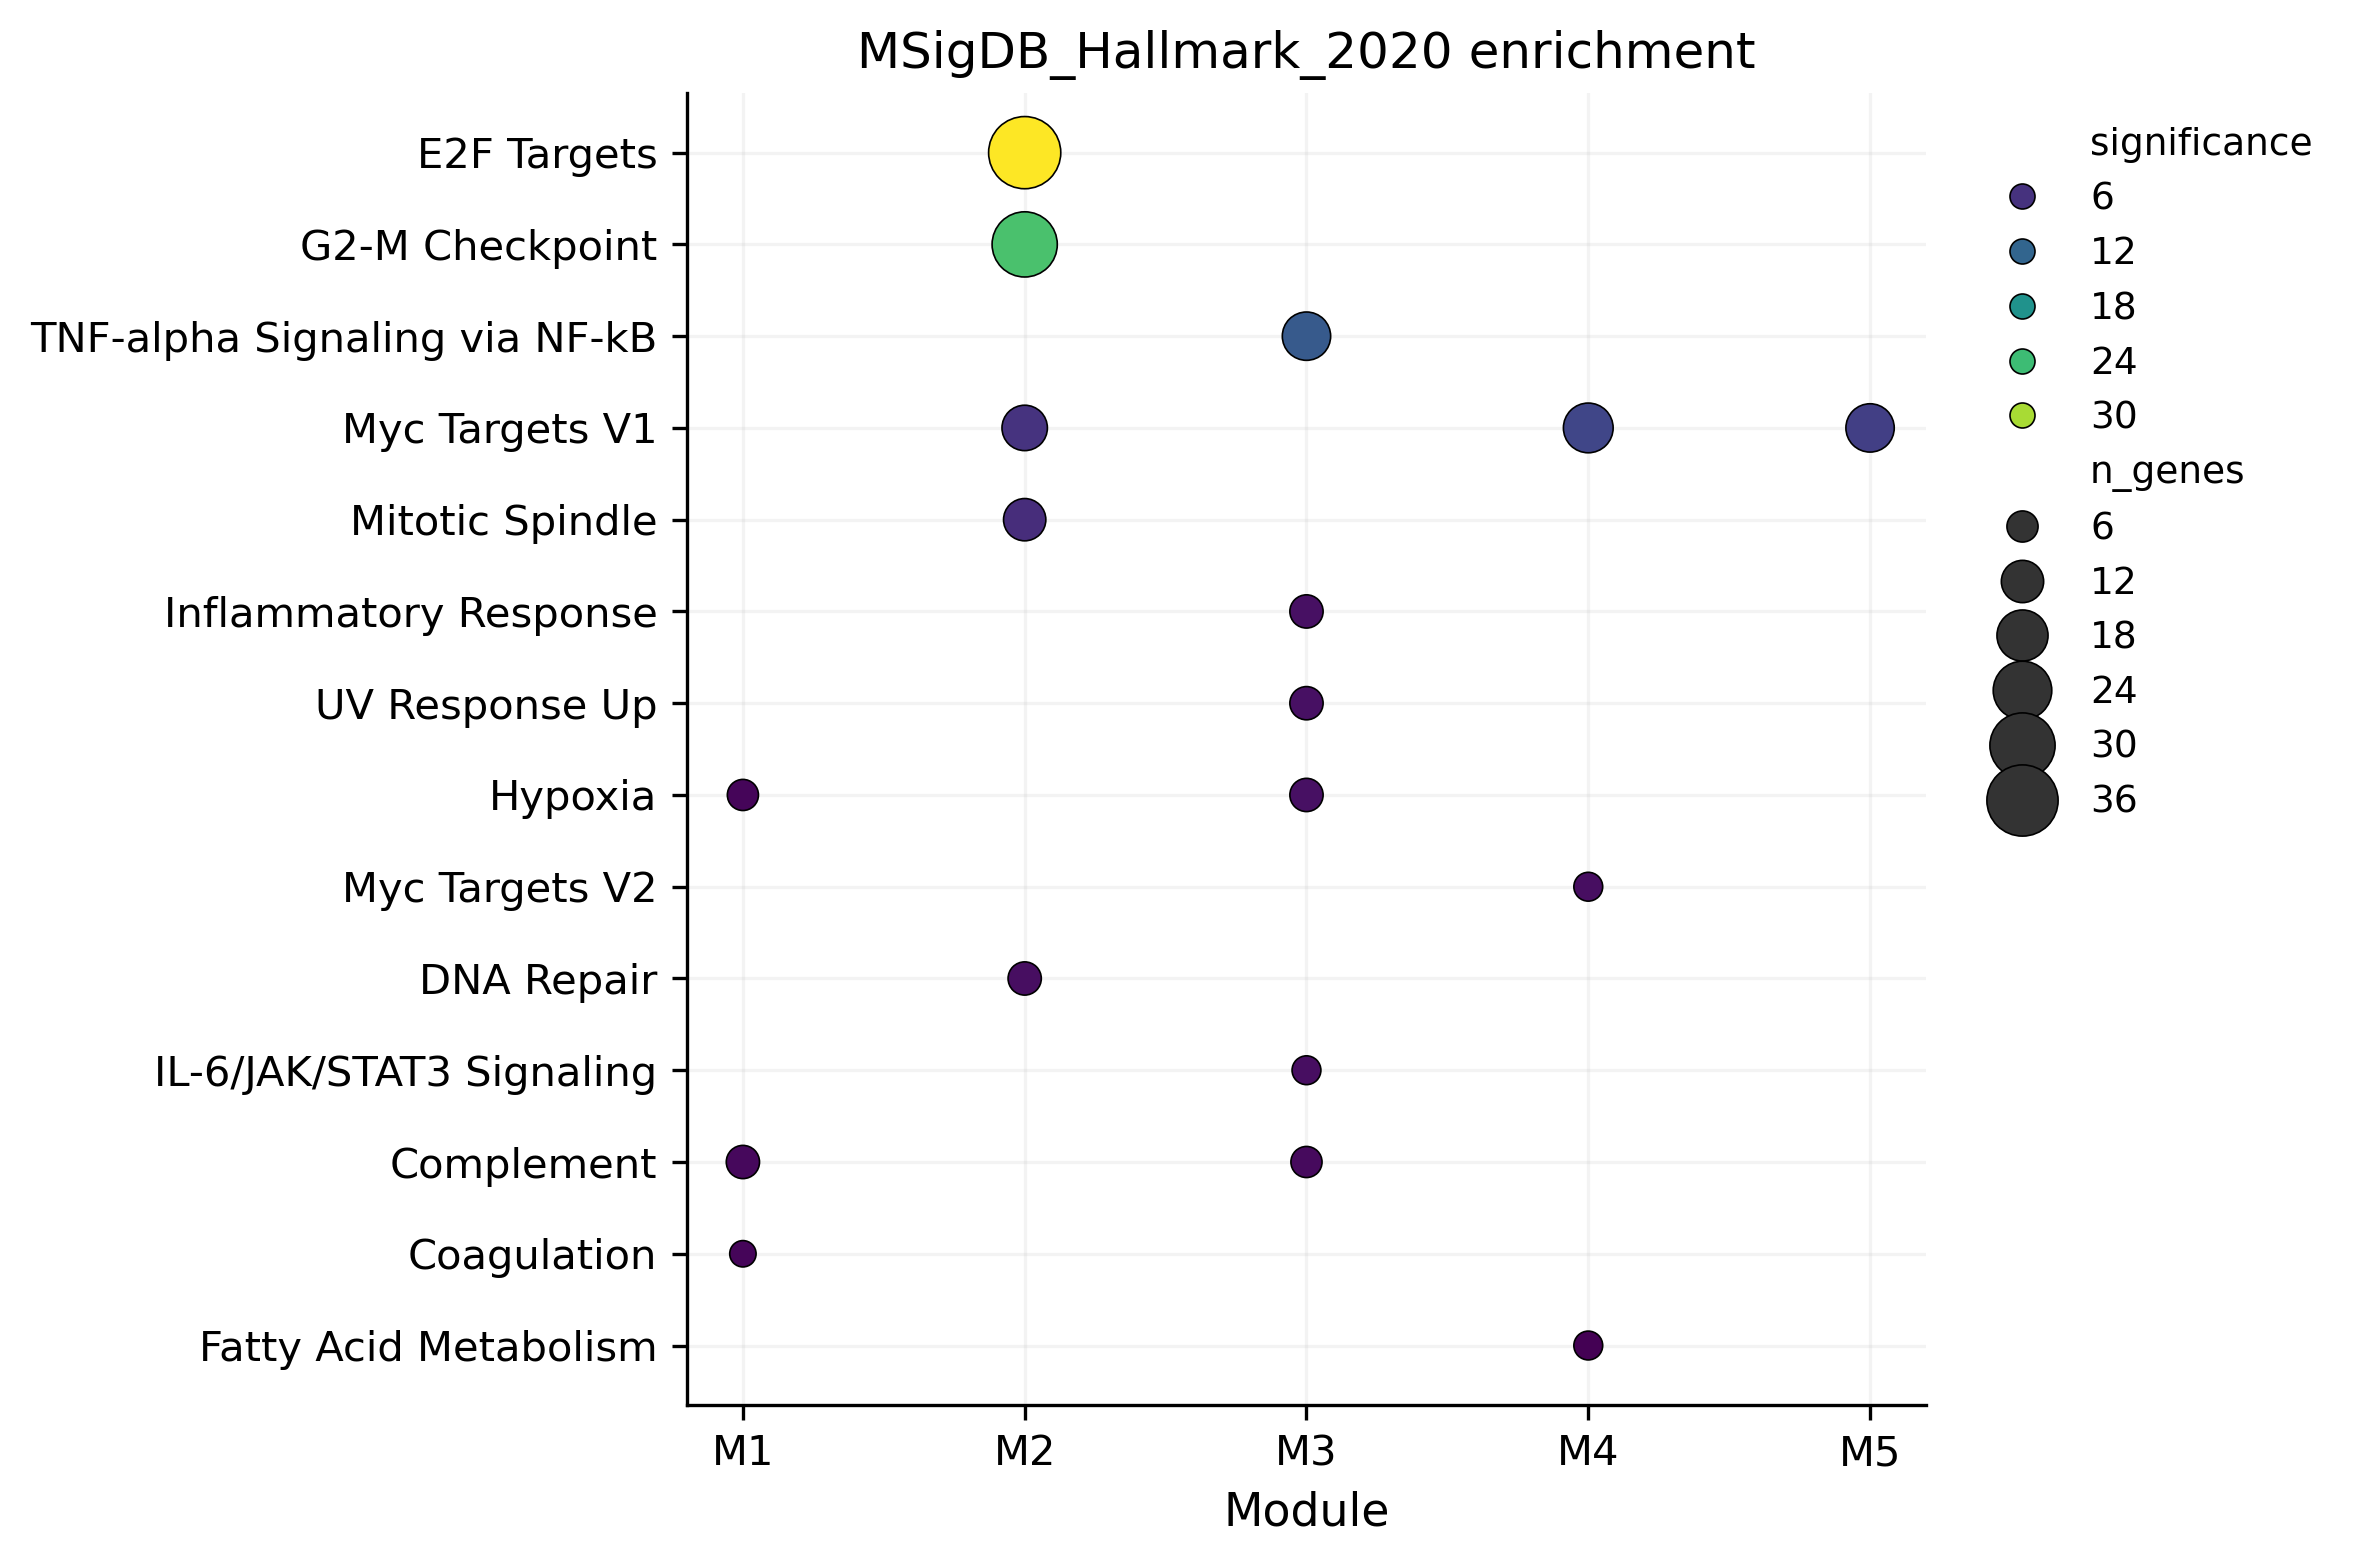

In [16]:
for database in databases:
    fig, ax = PlotWgcnaEnrichmentDotplot(
        enrichment_df,
        database=database,
        top_n=5,
        padj_cutoff=0.05,
    )
    if fig is not None:
        plt.show()

# Limits of interpretation

- Co-expression is observational evidence. The modules do not show causal
  regulation (for example, by a knocked-out gene) or physical interaction
  between genes.
- In a joint network of many groups, modules can follow the differences between
  groups (in the example dataset, maturation). They are not condition effects by
  themselves.
- The number of metacells is not the number of biological replicates. For
  comparisons between conditions, the unit is the sample. The example dataset
  has one sample per condition, so GF vs SPF differences are only hypotheses.